In [1]:
# ============================================================
# FINAL CNC TOOL WEAR + RUL PIPELINE
# Step 1 — Project Setup & File Verification
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import os

# ------------------------------------------------------------
# Project root
# ------------------------------------------------------------
PROJECT_ROOT = Path(".")

DATASET_DIR = PROJECT_ROOT / "dataset"
RESULTS_DIR = DATASET_DIR / "final_results"
MODELS_DIR = PROJECT_ROOT / "models"

# ------------------------------------------------------------
# Important files
# ------------------------------------------------------------
FILES = {
    "processed_features":
        DATASET_DIR / "processed_features.csv",

    "processed_features_temporal":
        DATASET_DIR / "processed_features_temporal.csv",

    "project_summary":
        RESULTS_DIR / "project_summary.json",

    "t9_rul":
        RESULTS_DIR / "t9_rul_estimates.csv",

    "t9_rolling_rul":
        RESULTS_DIR / "t9_rolling_rul_history.csv",

    "t9_drift":
        RESULTS_DIR / "t9_drift_analysis.csv",

    "t9_uncertainty":
        RESULTS_DIR / "t9_calibrated_uncertainty.csv",

    "t9_degradation":
        RESULTS_DIR / "t9_degradation_model_backtest.csv",

    "t9_wear_rate":
        RESULTS_DIR / "t9_wear_rate_predictions.csv",
}

# ------------------------------------------------------------
# Check paths
# ------------------------------------------------------------
print("=" * 60)
print("PROJECT FILE CHECK")
print("=" * 60)

for name, path in FILES.items():
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{name:30s} : {status}")
    print(f"   {path}")

print("\n" + "=" * 60)
print("DIRECTORIES")
print("=" * 60)

print("Dataset directory :", DATASET_DIR.resolve())
print("Results directory :", RESULTS_DIR.resolve())
print("Models directory  :", MODELS_DIR.resolve())

PROJECT FILE CHECK
processed_features             : FOUND
   dataset\processed_features.csv
processed_features_temporal    : FOUND
   dataset\processed_features_temporal.csv
project_summary                : FOUND
   dataset\final_results\project_summary.json
t9_rul                         : FOUND
   dataset\final_results\t9_rul_estimates.csv
t9_rolling_rul                 : FOUND
   dataset\final_results\t9_rolling_rul_history.csv
t9_drift                       : FOUND
   dataset\final_results\t9_drift_analysis.csv
t9_uncertainty                 : FOUND
   dataset\final_results\t9_calibrated_uncertainty.csv
t9_degradation                 : FOUND
   dataset\final_results\t9_degradation_model_backtest.csv
t9_wear_rate                   : FOUND
   dataset\final_results\t9_wear_rate_predictions.csv

DIRECTORIES
Dataset directory : C:\Users\udyak\OneDrive\Desktop\amp_project\dataset
Results directory : C:\Users\udyak\OneDrive\Desktop\amp_project\dataset\final_results
Models directory  : C:\

In [2]:
# ============================================================
# Step 1B — Show Available Files
# ============================================================

print("DATASET FILES")
print("-" * 50)

if DATASET_DIR.exists():
    for p in sorted(DATASET_DIR.iterdir()):
        if p.is_file():
            print(p.name)

print("\nFINAL RESULTS FILES")
print("-" * 50)

if RESULTS_DIR.exists():
    for p in sorted(RESULTS_DIR.iterdir()):
        if p.is_file():
            print(p.name)

print("\nMODEL FILES")
print("-" * 50)

if MODELS_DIR.exists():
    for p in sorted(MODELS_DIR.iterdir()):
        if p.is_file():
            print(p.name)

DATASET FILES
--------------------------------------------------
filelist.csv
live_model_history.csv
live_prediction_history.csv
M1T1R100C570VB55.h5
M1T1R101C574VB55.h5
M1T1R102C578VB55.h5
M1T1R103C582VB55.h5
M1T1R104C585VB55.h5
M1T1R105C589VB55.h5
M1T1R106C593VB55.h5
M1T1R107C597VB55.h5
M1T1R108C601VB55.h5
M1T1R109C621VB55.h5
M1T1R10C63VB14.h5
M1T1R110C625VB56.h5
M1T1R111C629VB56.h5
M1T1R112C633VB56.h5
M1T1R113C637VB56.h5
M1T1R114C640VB56.h5
M1T1R115C644VB56.h5
M1T1R116C648VB56.h5
M1T1R117C671VB56.h5
M1T1R118C675VB56.h5
M1T1R119C679VB56.h5
M1T1R11C67VB15.h5
M1T1R120C683VB56.h5
M1T1R121C687VB57.h5
M1T1R122C690VB57.h5
M1T1R123C694VB57.h5
M1T1R124C716VB57.h5
M1T1R125C720VB57.h5
M1T1R126C723VB57.h5
M1T1R127C727VB57.h5
M1T1R128C731VB57.h5
M1T1R129C735VB57.h5
M1T1R12C71VB16.h5
M1T1R130C739VB57.h5
M1T1R131C743VB57.h5
M1T1R132C747VB58.h5
M1T1R133C750VB58.h5
M1T1R134C754VB58.h5
M1T1R135C758VB58.h5
M1T1R136C762VB58.h5
M1T1R137C766VB58.h5
M1T1R138C786VB58.h5
M1T1R139C790VB58.h5
M1T1R13C75VB17.h5

In [3]:
# ============================================================
# Step 2 — Load Processed Data
# ============================================================

# Load main processed dataset
df = pd.read_csv(FILES["processed_features"])

# Load temporal dataset
df_temporal = pd.read_csv(FILES["processed_features_temporal"])

print("=" * 60)
print("MAIN DATASET")
print("=" * 60)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\n" + "=" * 60)
print("TEMPORAL DATASET")
print("=" * 60)

print("Shape:", df_temporal.shape)

print("\nColumns:")
print(df_temporal.columns.tolist())

print("\nFirst 5 rows:")
display(df_temporal.head())

MAIN DATASET
Shape: (6418, 42)

Columns:
['filename', 'machine', 'tool', 'run', 'contact_time', 'wear', 'fx_mean', 'fx_rms', 'fx_std', 'fx_peak', 'fx_min', 'fx_max', 'fy_mean', 'fy_rms', 'fy_std', 'fy_peak', 'fy_min', 'fy_max', 'fz_mean', 'fz_rms', 'fz_std', 'fz_peak', 'fz_min', 'fz_max', 'spindle_torque_mean', 'spindle_torque_rms', 'spindle_torque_std', 'spindle_torque_peak', 'spindle_torque_min', 'spindle_torque_max', 'deviation_x_mean', 'deviation_x_rms', 'deviation_x_std', 'deviation_x_peak', 'deviation_x_min', 'deviation_x_max', 'deviation_y_mean', 'deviation_y_rms', 'deviation_y_std', 'deviation_y_peak', 'deviation_y_min', 'deviation_y_max']

First 5 rows:


,filename,machine,tool,run,contact_time,wear,fx_mean,fx_rms,fx_std,fx_peak,...,deviation_x_std,deviation_x_peak,deviation_x_min,deviation_x_max,deviation_y_mean,deviation_y_rms,deviation_y_std,deviation_y_peak,deviation_y_min,deviation_y_max
0,M1T1R100C570VB55.h5,1,1,100,570.0,55,186.22331,213.06660,103.529030,526.41350,...,0.000504,0.00198,-0.00204,0.00198,-0.000009,0.000823,0.000823,0.00560,-0.00680,0.00560
1,M1T1R101C574VB55.h5,1,1,101,574.0,55,188.03804,214.76166,103.750980,522.51117,...,0.000546,0.00192,-0.00199,0.00192,-0.000011,0.000835,0.000835,0.00552,-0.00695,0.00552
2,M1T1R102C578VB55.h5,1,1,102,578.0,55,189.58600,216.50273,104.549390,519.88800,...,0.000471,0.00191,-0.00202,0.00191,-0.000010,0.000839,0.000839,0.00561,-0.00689,0.00561
3,M1T1R103C582VB55.h5,1,1,103,582.0,55,190.69272,217.85565,105.344086,514.40480,...,0.000536,0.00223,-0.00196,0.00223,-0.000010,0.000840,0.000840,0.00559,-0.00686,0.00559
4,M1T1R104C585VB55.h5,1,1,104,585.0,55,191.46834,218.92316,106.147170,528.67126,...,0.000505,0.00185,-0.00196,0.00185,-0.000011,0.000835,0.000835,0.00559,-0.00679,0.00559



TEMPORAL DATASET
Shape: (6418, 66)

Columns:
['filename', 'machine', 'tool', 'run', 'contact_time', 'wear', 'fx_mean', 'fx_rms', 'fx_std', 'fx_peak', 'fx_min', 'fx_max', 'fy_mean', 'fy_rms', 'fy_std', 'fy_peak', 'fy_min', 'fy_max', 'fz_mean', 'fz_rms', 'fz_std', 'fz_peak', 'fz_min', 'fz_max', 'spindle_torque_mean', 'spindle_torque_rms', 'spindle_torque_std', 'spindle_torque_peak', 'spindle_torque_min', 'spindle_torque_max', 'deviation_x_mean', 'deviation_x_rms', 'deviation_x_std', 'deviation_x_peak', 'deviation_x_min', 'deviation_x_max', 'deviation_y_mean', 'deviation_y_rms', 'deviation_y_std', 'deviation_y_peak', 'deviation_y_min', 'deviation_y_max', 'fx_mean_delta', 'fx_mean_rate', 'fx_mean_rolling_mean', 'fx_mean_rolling_std', 'fx_rms_delta', 'fx_rms_rate', 'fx_rms_rolling_mean', 'fx_rms_rolling_std', 'fy_mean_delta', 'fy_mean_rate', 'fy_mean_rolling_mean', 'fy_mean_rolling_std', 'fy_rms_delta', 'fy_rms_rate', 'fy_rms_rolling_mean', 'fy_rms_rolling_std', 'fz_mean_delta', 'fz_mean_r

,filename,machine,tool,run,contact_time,wear,fx_mean,fx_rms,fx_std,fx_peak,...,fy_rms_rolling_mean,fy_rms_rolling_std,fz_mean_delta,fz_mean_rate,fz_mean_rolling_mean,fz_mean_rolling_std,spindle_torque_rms_delta,spindle_torque_rms_rate,spindle_torque_rms_rolling_mean,spindle_torque_rms_rolling_std
0,M1T1R1C11VB3.h5,1,1,1,11.0,3,140.13017,169.01994,94.50544,408.94030,...,41.429660,0.000000,0.000000,0.000000,23.692034,0.000000,0.000000,0.000000,1.077499,0.000000
1,M1T1R2C15VB3.h5,1,1,2,15.0,3,142.04657,170.65767,94.58759,426.87732,...,41.245663,0.260212,-0.164376,-0.041094,23.609846,0.116231,0.003649,0.000912,1.079323,0.002580
2,M1T1R3C19VB4.h5,1,1,3,19.0,4,143.78740,172.11060,94.58984,430.00632,...,41.040988,0.399413,-0.346139,-0.086535,23.467070,0.260595,0.003930,0.000982,1.081241,0.003790
3,M1T1R4C23VB5.h5,1,1,4,23.0,5,145.02786,173.20052,94.68546,426.12933,...,40.876263,0.463562,-0.210408,-0.052602,23.343080,0.326752,0.002845,0.000711,1.082911,0.004554
4,M1T1R5C27VB6.h5,1,1,5,27.0,6,145.80566,173.94687,94.85898,422.25253,...,40.840952,0.409148,-0.347328,-0.086832,23.199221,0.428431,-0.000224,-0.000056,1.083869,0.004487


In [4]:
# ============================================================
# Step 2B — Load Project Summary
# ============================================================

with open(FILES["project_summary"], "r") as f:
    project_summary = json.load(f)

print("=" * 60)
print("PROJECT SUMMARY")
print("=" * 60)

for key, value in project_summary.items():
    print(f"{key}: {value}")

PROJECT SUMMARY
dataset_rows: 6418
best_model: Optimized Extra Trees
best_model_t9_mae_um: 10.57
best_model_t9_r2: 0.837
late_wear_mae_um: 24.923
training_tools: [1, 2, 4, 5]
validation_tools: [3, 6]
live_tools: [7, 8]
final_test_tool: 9
current_t9_wear_um: 160
current_t9_contact_time_s: 3449
provisional_eol_um: 300
rolling_rul_50_sample_min: 27.79
important_conclusion: Current wear prediction is reliable enough for the project, but future wear-rate prediction and long-term RUL extrapolation are not fully validated.
next_step: Use Extra Trees predicted wear as input to rolling RUL engine.


In [5]:
# ============================================================
# Step 3 — Identify Previous Model Feature Set
# ============================================================

# Show all result files available
result_files = sorted(RESULTS_DIR.glob("*"))

print("Available final-result files:")
for f in result_files:
    print(" -", f.name)

print("\nTotal:", len(result_files))

Available final-result files:
 - drift_aware_model_history.csv
 - extraction_errors.csv
 - final_training_data.csv
 - leave_one_machine_out_results.csv
 - live_model_history.csv
 - machine_normalization_results.csv
 - processed_features.csv
 - processed_features_temporal.csv
 - project_summary.json
 - same_domain_extra_trees_predictions.csv
 - same_domain_region_results.csv
 - same_domain_tool_results.csv
 - t9_ann_predictions.csv
 - t9_calibrated_uncertainty.csv
 - t9_degradation_model_backtest.csv
 - t9_drift_analysis.csv
 - t9_extra_trees_uncertainty.csv
 - t9_gru_predictions.csv
 - t9_lstm_predictions.csv
 - t9_rolling_rul_history.csv
 - t9_rul_estimates.csv
 - t9_wear_rate_predictions.csv
 - wear_rate_feature_importance.csv
 - wear_weighted_extra_trees_results.csv

Total: 24


In [6]:
# ============================================================
# Step 3 — Find Extra Trees Result Files Anywhere
# ============================================================

print("Searching entire project for Extra Trees files...\n")

for pattern in ["*extra*trees*", "*Extra*Trees*", "*importance*"]:
    print(f"--- {pattern} ---")
    matches = list(PROJECT_ROOT.rglob(pattern))
    
    for f in matches:
        print(f)
    print()

Searching entire project for Extra Trees files...

--- *extra*trees* ---
dataset\optimized_extra_trees_importance.csv
dataset\optimized_extra_trees_results.csv
dataset\same_domain_extra_trees_predictions.csv
dataset\t9_extra_trees_uncertainty.csv
dataset\wear_weighted_extra_trees_results.csv
models\extra_trees_final.pkl
dataset\final_results\same_domain_extra_trees_predictions.csv
dataset\final_results\t9_extra_trees_uncertainty.csv
dataset\final_results\wear_weighted_extra_trees_results.csv

--- *Extra*Trees* ---
dataset\optimized_extra_trees_importance.csv
dataset\optimized_extra_trees_results.csv
dataset\same_domain_extra_trees_predictions.csv
dataset\t9_extra_trees_uncertainty.csv
dataset\wear_weighted_extra_trees_results.csv
models\extra_trees_final.pkl
dataset\final_results\same_domain_extra_trees_predictions.csv
dataset\final_results\t9_extra_trees_uncertainty.csv
dataset\final_results\wear_weighted_extra_trees_results.csv

--- *importance* ---
feature importance.png
dataset\opt

In [7]:
# ============================================================
# Step 3B — Inspect Any Extra Trees Result Files Found
# ============================================================

matches = list(PROJECT_ROOT.rglob("*extra*trees*"))

for path in matches:
    print("\n" + "=" * 70)
    print(path)
    print("=" * 70)
    
    try:
        temp = pd.read_csv(path)
        print("Shape:", temp.shape)
        print("Columns:", temp.columns.tolist())
        display(temp.head(10))
    except Exception as e:
        print("Could not read:", e)


dataset\optimized_extra_trees_importance.csv
Shape: (23, 2)
Columns: ['feature', 'importance']


,feature,importance
0,fy_mean,0.232871
1,fx_mean,0.213082
2,fx_rms,0.150243
3,contact_time,0.127402
4,fz_mean,0.105835
5,spindle_torque_rms,0.052593
6,deviation_y_rms,0.041003
7,fy_rms,0.016850
8,fx_std,0.014145
9,fy_std,0.007395



dataset\optimized_extra_trees_results.csv
Shape: (2, 4)
Columns: ['Dataset', 'MAE', 'RMSE', 'R2']


,Dataset,MAE,RMSE,R2
0,"Validation (T3,T6)",3.399231,4.833539,0.972021
1,T9 Final Test,10.569986,13.779348,0.836802



dataset\same_domain_extra_trees_predictions.csv
Shape: (616, 45)
Columns: ['filename', 'machine', 'tool', 'run', 'contact_time', 'wear', 'fx_mean', 'fx_rms', 'fx_std', 'fx_peak', 'fx_min', 'fx_max', 'fy_mean', 'fy_rms', 'fy_std', 'fy_peak', 'fy_min', 'fy_max', 'fz_mean', 'fz_rms', 'fz_std', 'fz_peak', 'fz_min', 'fz_max', 'spindle_torque_mean', 'spindle_torque_rms', 'spindle_torque_std', 'spindle_torque_peak', 'spindle_torque_min', 'spindle_torque_max', 'deviation_x_mean', 'deviation_x_rms', 'deviation_x_std', 'deviation_x_peak', 'deviation_x_min', 'deviation_x_max', 'deviation_y_mean', 'deviation_y_rms', 'deviation_y_std', 'deviation_y_peak', 'deviation_y_min', 'deviation_y_max', 'predicted_wear', 'absolute_error', 'wear_region']


,filename,machine,tool,run,contact_time,wear,fx_mean,fx_rms,fx_std,fx_peak,...,deviation_x_max,deviation_y_mean,deviation_y_rms,deviation_y_std,deviation_y_peak,deviation_y_min,deviation_y_max,predicted_wear,absolute_error,wear_region
0,M1T1R488C2777VB114.h5,1,1,488,2777.0,114,363.30786,406.80133,183.01556,1200.00830,...,0.00364,-0.000015,0.000935,0.000935,0.00601,-0.00678,0.00601,113.09125,0.90875,Late
1,M1T1R489C2781VB115.h5,1,1,489,2781.0,115,363.48758,406.76862,182.58551,1171.54250,...,0.00343,-0.000014,0.000941,0.000940,0.00586,-0.00678,0.00586,112.76250,2.23750,Late
2,M1T1R490C2785VB115.h5,1,1,490,2785.0,115,361.35587,404.73685,182.30150,1190.06350,...,0.00349,-0.000016,0.000922,0.000922,0.00600,-0.00665,0.00600,111.63000,3.37000,Late
3,M1T1R491C2789VB115.h5,1,1,491,2789.0,115,357.04163,398.66653,177.35912,1154.78360,...,0.00370,-0.000016,0.000927,0.000927,0.00613,-0.00651,0.00613,108.59750,6.40250,Late
4,M1T1R492C2793VB115.h5,1,1,492,2793.0,115,356.92947,398.39688,176.97859,1178.27750,...,0.00351,-0.000015,0.000926,0.000926,0.00618,-0.00677,0.00618,111.23000,3.77000,Late
5,M1T1R493C2796VB115.h5,1,1,493,2796.0,115,357.07516,398.80872,177.61115,1177.59130,...,0.00339,-0.000015,0.000945,0.000945,0.00620,-0.00686,0.00620,110.54375,4.45625,Late
6,M1T1R494C2820VB116.h5,1,1,494,2820.0,116,330.50635,368.82490,163.69897,963.61920,...,0.00296,-0.000009,0.000899,0.000899,0.00526,-0.00665,0.00526,107.50625,8.49375,Late
7,M1T1R495C2823VB116.h5,1,1,495,2823.0,116,334.58038,372.39673,163.50926,966.74920,...,0.00312,-0.000011,0.000909,0.000909,0.00538,-0.00676,0.00538,108.52375,7.47625,Late
8,M1T1R496C2827VB117.h5,1,1,496,2827.0,117,336.25018,373.80997,163.30862,949.52185,...,0.00326,-0.000012,0.000906,0.000906,0.00548,-0.00680,0.00548,108.65625,8.34375,Late
9,M1T1R497C2831VB117.h5,1,1,497,2831.0,117,339.23105,377.49115,165.59538,980.87320,...,0.00313,-0.000010,0.000917,0.000917,0.00547,-0.00674,0.00547,108.81125,8.18875,Late


... (6 outputs left out)


dataset\final_results\t9_extra_trees_uncertainty.csv
Shape: (609, 8)
Columns: ['contact_time', 'actual_wear', 'predicted_wear', 'tree_uncertainty', 'lower_90', 'upper_90', 'absolute_error', 'region']


,contact_time,actual_wear,predicted_wear,tree_uncertainty,lower_90,upper_90,absolute_error,region
0,12.0,3,12.52625,18.048042,4.24875,20.80375,9.52625,Early
1,15.0,4,13.13375,18.081921,4.85625,21.41125,9.13375,Early
2,19.0,4,14.26250,17.682296,5.98500,22.54000,10.26250,Early
3,23.0,5,15.68375,17.434627,7.40625,23.96125,10.68375,Early
4,27.0,6,17.28375,16.873225,9.00625,25.56125,11.28375,Early
5,31.0,7,18.45000,16.588927,10.17250,26.72750,11.45000,Early
6,35.0,8,19.77625,16.455126,11.49875,28.05375,11.77625,Early
7,56.0,13,26.68250,14.855359,18.40500,34.96000,13.68250,Early
8,60.0,14,27.51375,14.783684,19.23625,35.79125,13.51375,Early
9,64.0,15,28.18375,14.613777,19.90625,36.46125,13.18375,Early



dataset\final_results\wear_weighted_extra_trees_results.csv
Shape: (4, 7)
Columns: ['Model', 'MAE', 'RMSE', 'R2', 'Early_MAE', 'Middle_MAE', 'Late_MAE']


,Model,MAE,RMSE,R2,Early_MAE,Middle_MAE,Late_MAE
0,Normal,22.974077,26.787015,-2.385765,NaN,4.475759,27.311358
1,Moderate,23.209621,27.024106,-2.445964,NaN,4.614733,27.569544
2,Strong,23.280321,27.090560,-2.462933,NaN,4.680043,27.641508
3,Very Strong,23.313685,27.139792,-2.475531,NaN,4.680748,27.682530


In [8]:
# ============================================================
# Step 4 — Load Saved Extra Trees Model
# ============================================================

import joblib

MODEL_PATH = MODELS_DIR / "extra_trees_final.pkl"

print("Model path:", MODEL_PATH)
print("Exists:", MODEL_PATH.exists())

model = joblib.load(MODEL_PATH)

print("\nModel loaded successfully.")
print("Model type:", type(model))

Model path: models\extra_trees_final.pkl
Exists: True

Model loaded successfully.
Model type: <class 'sklearn.ensemble._forest.ExtraTreesRegressor'>


In [9]:
# ============================================================
# Step 4B — Inspect Model
# ============================================================

print("Number of estimators:", model.n_estimators)

if hasattr(model, "max_depth"):
    print("Max depth:", model.max_depth)

if hasattr(model, "n_features_in_"):
    print("Number of input features:", model.n_features_in_)

if hasattr(model, "feature_importances_"):
    print("Feature importance length:", len(model.feature_importances_))

Number of estimators: 800
Max depth: 30
Number of input features: 23
Feature importance length: 23


In [10]:
# ============================================================
# Step 5 — Identify Exact Model Features
# ============================================================

# Feature importance from the saved model
model_importance = pd.DataFrame({
    "feature": df.columns[:model.n_features_in_],
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

print("Model feature count:", len(model_importance))

display(model_importance)

Model feature count: 23


,feature,importance
4,contact_time,0.232871
0,filename,0.213082
1,machine,0.150243
22,fz_min,0.127402
8,fx_std,0.105835
13,fy_rms,0.052593
20,fz_std,0.041003
5,wear,0.016850
2,tool,0.014145
6,fx_mean,0.007395


In [11]:
# ============================================================
# Step 5B — Compare Against Saved Result
# ============================================================

importance_path = PROJECT_ROOT / "dataset" / "optimized_extra_trees_importance.csv"

saved_importance = pd.read_csv(importance_path)

print("Saved feature list:")
display(saved_importance)

print("\nCurrent model feature importance:")
display(model_importance)

Saved feature list:


,feature,importance
0,fy_mean,0.232871
1,fx_mean,0.213082
2,fx_rms,0.150243
3,contact_time,0.127402
4,fz_mean,0.105835
5,spindle_torque_rms,0.052593
6,deviation_y_rms,0.041003
7,fy_rms,0.016850
8,fx_std,0.014145
9,fy_std,0.007395



Current model feature importance:


,feature,importance
4,contact_time,0.232871
0,filename,0.213082
1,machine,0.150243
22,fz_min,0.127402
8,fx_std,0.105835
13,fy_rms,0.052593
20,fz_std,0.041003
5,wear,0.016850
2,tool,0.014145
6,fx_mean,0.007395


In [12]:
# ============================================================
# Step 5 — Extract Exact Feature Order From Saved Model
# ============================================================

if hasattr(model, "feature_names_in_"):
    MODEL_FEATURES = list(model.feature_names_in_)

    print("Model has stored feature names.")
    print("\nExact feature order used during training:\n")

    for i, feature in enumerate(MODEL_FEATURES):
        print(f"{i:2d}. {feature}")

else:
    print("Model does not contain feature_names_in_.")

Model has stored feature names.

Exact feature order used during training:

 0. fx_mean
 1. fx_rms
 2. fx_std
 3. fx_min
 4. fy_mean
 5. fy_rms
 6. fy_std
 7. fy_min
 8. fz_mean
 9. fz_rms
10. fz_std
11. fz_min
12. spindle_torque_mean
13. spindle_torque_rms
14. spindle_torque_std
15. spindle_torque_min
16. deviation_x_mean
17. deviation_x_rms
18. deviation_x_min
19. deviation_y_mean
20. deviation_y_rms
21. deviation_y_min
22. contact_time


In [13]:
# ============================================================
# Step 5B — Verify Features Exist in Current Dataset
# ============================================================

missing_features = [
    f for f in MODEL_FEATURES
    if f not in df.columns
]

print("Number of model features:", len(MODEL_FEATURES))
print("Missing from current dataset:", missing_features)

if not missing_features:
    print("\n✓ All 23 model features are available.")

Number of model features: 23
Missing from current dataset: []

✓ All 23 model features are available.


In [14]:
# ============================================================
# Step 6 — T9 Model Prediction Verification
# ============================================================

# Select T9
t9 = df[df["tool"] == 9].copy()

# Prepare features in EXACT training order
X_t9 = t9[MODEL_FEATURES]
y_t9 = t9["wear"]

# Predict
t9["predicted_wear"] = model.predict(X_t9)

print("T9 samples:", len(t9))
print("\nFirst predictions:")
display(
    t9[["contact_time", "wear", "predicted_wear"]].head(10)
)

T9 samples: 609

First predictions:


,contact_time,wear,predicted_wear
5809,569.0,51,56.60375
5810,573.0,51,56.77375
5811,577.0,51,56.86125
5812,581.0,51,57.11125
5813,585.0,51,57.44875
5814,589.0,51,57.78375
5815,592.0,51,57.65375
5816,596.0,51,57.61000
5817,600.0,52,58.44125
5818,620.0,52,59.21750


In [15]:
# ============================================================
# Step 6B — Verify T9 Performance
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(t9["wear"], t9["predicted_wear"])
rmse = np.sqrt(mean_squared_error(t9["wear"], t9["predicted_wear"]))
r2 = r2_score(t9["wear"], t9["predicted_wear"])

print(f"T9 MAE  : {mae:.4f} µm")
print(f"T9 RMSE : {rmse:.4f} µm")
print(f"T9 R²   : {r2:.4f}")

T9 MAE  : 10.5700 µm
T9 RMSE : 13.7793 µm
T9 R²   : 0.8368


In [16]:
# ============================================================
# Step 7 — Build T9 Predicted Wear History
# ============================================================

t9 = t9.sort_values("contact_time").reset_index(drop=True)

# Calculate prediction error
t9["prediction_error"] = t9["predicted_wear"] - t9["wear"]
t9["absolute_error"] = abs(t9["prediction_error"])

# Rolling predicted wear
t9["predicted_wear_rolling_mean"] = (
    t9["predicted_wear"]
    .rolling(window=50, min_periods=1)
    .mean()
)

# Rolling wear rate: µm / second
t9["predicted_wear_rate"] = (
    t9["predicted_wear_rolling_mean"]
    .diff()
    / t9["contact_time"].diff()
)

print("T9 prediction history created.")
display(
    t9[
        [
            "contact_time",
            "wear",
            "predicted_wear",
            "predicted_wear_rolling_mean",
            "predicted_wear_rate"
        ]
    ].tail(15)
)

T9 prediction history created.


,contact_time,wear,predicted_wear,predicted_wear_rolling_mean,predicted_wear_rate
594,3379.0,154,115.36875,111.421250,0.024925
595,3383.0,154,115.66125,111.513925,0.023169
596,3387.0,155,115.45750,111.598675,0.021187
597,3390.0,155,116.61500,111.712750,0.038025
598,3394.0,155,116.75875,111.822750,0.027500
599,3398.0,156,117.53875,111.947375,0.031156
600,3402.0,156,117.49500,112.072275,0.031225
601,3422.0,157,117.88125,112.290250,0.010899
602,3426.0,158,118.76250,112.527950,0.059425
603,3430.0,158,118.98375,112.746275,0.054581


In [17]:
# ============================================================
# Step 7B — Basic Wear-Rate Statistics
# ============================================================

rate = t9["predicted_wear_rate"].dropna()

print("Predicted wear-rate statistics")
print("-" * 40)
print(f"Mean   : {rate.mean():.6f} µm/s")
print(f"Median : {rate.median():.6f} µm/s")
print(f"Std    : {rate.std():.6f} µm/s")
print(f"Min    : {rate.min():.6f} µm/s")
print(f"Max    : {rate.max():.6f} µm/s")

Predicted wear-rate statistics
----------------------------------------
Mean   : 0.039717 µm/s
Median : 0.028454 µm/s
Std    : 0.036926 µm/s
Min    : 0.000799 µm/s
Max    : 0.285803 µm/s


In [18]:
# ============================================================
# Step 8 — Robust Recent Wear-Rate Estimation
# ============================================================

from scipy.stats import linregress

# Use recent 100 samples to estimate current degradation trend
WINDOW = 100

recent = t9.tail(WINDOW).copy()

# Linear regression: predicted wear vs contact time
slope, intercept, r_value, p_value, std_err = linregress(
    recent["contact_time"],
    recent["predicted_wear"]
)

current_predicted_wear = t9["predicted_wear"].iloc[-1]
current_actual_wear = t9["wear"].iloc[-1]
current_time = t9["contact_time"].iloc[-1]

EOL_WEAR = 300.0

remaining_wear = EOL_WEAR - current_predicted_wear

if slope > 0:
    estimated_rul_seconds = remaining_wear / slope
    estimated_rul_minutes = estimated_rul_seconds / 60
else:
    estimated_rul_seconds = np.inf
    estimated_rul_minutes = np.inf

print("=" * 60)
print("ROBUST DEGRADATION ESTIMATE")
print("=" * 60)

print(f"Window size              : {WINDOW} samples")
print(f"Current contact time     : {current_time:.1f} s")
print(f"Current actual wear      : {current_actual_wear:.2f} µm")
print(f"Current predicted wear   : {current_predicted_wear:.2f} µm")
print(f"EOL threshold            : {EOL_WEAR:.1f} µm")
print(f"Remaining predicted wear : {remaining_wear:.2f} µm")
print(f"\nRecent wear rate         : {slope:.6f} µm/s")
print(f"Recent wear rate         : {slope * 60:.3f} µm/min")
print(f"Trend R²                 : {r_value**2:.4f}")
print(f"\nEstimated RUL            : {estimated_rul_minutes:.2f} min")

ROBUST DEGRADATION ESTIMATE
Window size              : 100 samples
Current contact time     : 3449.0 s
Current actual wear      : 160.00 µm
Current predicted wear   : 119.53 µm
EOL threshold            : 300.0 µm
Remaining predicted wear : 180.47 µm

Recent wear rate         : 0.024438 µm/s
Recent wear rate         : 1.466 µm/min
Trend R²                 : 0.8175

Estimated RUL            : 123.08 min


In [19]:
# ============================================================
# Step 9 — RUL Backtest on T9
# ============================================================

EOL_WEAR = 300.0
WINDOW = 100

# Actual T9 EOL
eol_rows = t9[t9["wear"] >= EOL_WEAR]

if len(eol_rows) == 0:
    print("T9 does not reach the 300 µm EOL threshold.")
else:
    actual_eol_time = eol_rows["contact_time"].iloc[0]

    checkpoints = [150, 200, 250, 300, 350, 400, 450, 500]

    results = []

    for n in checkpoints:

        if n >= len(t9):
            continue

        history = t9.iloc[:n].copy()

        recent = history.tail(min(WINDOW, len(history)))

        slope, intercept, r_value, p_value, std_err = linregress(
            recent["contact_time"],
            recent["predicted_wear"]
        )

        current_time = history["contact_time"].iloc[-1]
        current_pred = history["predicted_wear"].iloc[-1]

        actual_current_wear = history["wear"].iloc[-1]

        remaining_wear = EOL_WEAR - current_pred

        if slope > 0:
            predicted_rul_sec = remaining_wear / slope
            predicted_rul_min = predicted_rul_sec / 60
        else:
            predicted_rul_min = np.nan

        actual_rul_min = (actual_eol_time - current_time) / 60

        results.append({
            "samples_used": n,
            "contact_time_s": current_time,
            "actual_wear_um": actual_current_wear,
            "predicted_wear_um": current_pred,
            "wear_error_um": current_pred - actual_current_wear,
            "wear_rate_um_s": slope,
            "trend_r2": r_value**2,
            "predicted_rul_min": predicted_rul_min,
            "actual_rul_min": actual_rul_min,
            "rul_error_min": predicted_rul_min - actual_rul_min
        })

    rul_backtest = pd.DataFrame(results)

    print("=" * 80)
    print("T9 RUL BACKTEST")
    print("=" * 80)

    print(f"Actual EOL contact time : {actual_eol_time:.1f} s")
    print(f"EOL wear threshold      : {EOL_WEAR:.1f} µm")
    print(f"Window                  : {WINDOW} samples\n")

    display(
        rul_backtest.round(3)
    )

    valid = rul_backtest["rul_error_min"].dropna()

    print("\n" + "-" * 50)
    print("BACKTEST SUMMARY")
    print("-" * 50)
    print(f"RUL MAE  : {valid.abs().mean():.2f} min")
    print(f"RUL RMSE : {np.sqrt((valid**2).mean()):.2f} min")

T9 does not reach the 300 µm EOL threshold.


In [20]:
# ============================================================
# Step 9 — Inspect Existing RUL Work
# ============================================================

rul_files = {
    "rul_estimates": RESULTS_DIR / "t9_rul_estimates.csv",
    "rolling_rul": RESULTS_DIR / "t9_rolling_rul_history.csv",
    "degradation_backtest": RESULTS_DIR / "t9_degradation_model_backtest.csv",
    "wear_rate": RESULTS_DIR / "t9_wear_rate_predictions.csv",
}

for name, path in rul_files.items():
    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    if path.exists():
        temp = pd.read_csv(path)
        print("Shape:", temp.shape)
        print("Columns:", temp.columns.tolist())
        display(temp.head(5))
        print("\nLast 5 rows:")
        display(temp.tail(5))
    else:
        print("FILE NOT FOUND:", path)


RUL_ESTIMATES
Shape: (3, 4)
Columns: ['EOL threshold (µm)', 'Estimated EOL time (s)', 'RUL (s)', 'RUL (min)']


,EOL threshold (µm),Estimated EOL time (s),RUL (s),RUL (min)
0,200,4096.032352,647.032352,10.783873
1,250,4638.059453,1189.059453,19.817658
2,300,5081.081604,1632.081604,27.201360



Last 5 rows:


,EOL threshold (µm),Estimated EOL time (s),RUL (s),RUL (min)
0,200,4096.032352,647.032352,10.783873
1,250,4638.059453,1189.059453,19.817658
2,300,5081.081604,1632.081604,27.201360



ROLLING_RUL
Shape: (4941, 6)
Columns: ['sample', 'contact_time', 'actual_wear', 'window', 'EOL', 'predicted_RUL_s']


,sample,contact_time,actual_wear,window,EOL,predicted_RUL_s
0,30,176.0,38.0,30,200,712.253548
1,31,180.0,38.0,30,200,725.429892
2,32,184.0,38.0,30,200,739.888635
3,33,188.0,38.0,30,200,760.863691
4,34,192.0,38.0,30,200,784.943715


... (6 outputs left out)


WEAR_RATE
Shape: (607, 6)
Columns: ['contact_time', 'actual_wear', 'actual_wear_rate', 'predicted_wear_rate', 'rate_error', 'wear_region']


,contact_time,actual_wear,actual_wear_rate,predicted_wear_rate,rate_error,wear_region
0,19.0,4,0.00,0.180259,0.180259,Early
1,23.0,5,0.25,0.174762,0.075238,Early
2,27.0,6,0.25,0.175092,0.074908,Early
3,31.0,7,0.25,0.175174,0.074826,Early
4,35.0,8,0.25,0.175394,0.074606,Early



Last 5 rows:


,contact_time,actual_wear,actual_wear_rate,predicted_wear_rate,rate_error,wear_region
602,3434.0,158,0.00,0.112958,0.112958,Late
603,3438.0,159,0.25,0.109214,0.140786,Late
604,3441.0,159,0.00,0.109602,0.109602,Late
605,3445.0,159,0.00,0.105266,0.105266,Late
606,3449.0,160,0.25,0.109139,0.140861,Late


WEAR-REGION ERROR ANALYSIS


,wear_region,samples,actual_mean,predicted_mean,MAE,mean_residual
0,<50,726,37.096,40.713,4.296,-3.616
1,50-100,4135,73.148,74.123,2.031,-0.975
2,100-150,1502,122.619,117.989,6.597,4.629
3,150-200,55,153.982,130.247,23.735,23.735
4,200-250,0,NaN,NaN,NaN,NaN
5,>250,0,NaN,NaN,NaN,NaN


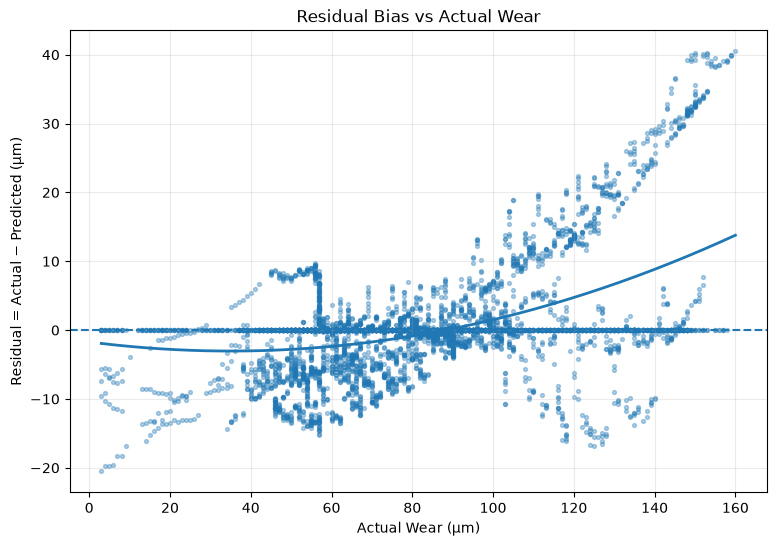


T9 DISTRIBUTION SHIFT — TOP FEATURES


,feature,training_mean,training_std,t9_mean,t9_min,t9_max,mean_shift_z
21,deviation_y_min,-0.0067,0.0003,-0.0020,-0.0022,-0.0014,16.3076
20,deviation_y_rms,0.0009,0.0001,0.0003,0.0002,0.0005,8.0312
2,fx_std,156.5427,29.8862,300.0311,226.3840,462.8196,4.8012
3,fx_min,-434.4627,197.4606,-1019.2231,-1296.3787,-712.5943,2.9614
7,fy_min,-256.7999,88.0270,-496.6863,-1134.2952,-186.3582,2.7251
13,spindle_torque_rms,1.3767,0.1388,1.0718,0.9097,1.2356,2.1962
14,spindle_torque_std,0.4858,0.0937,0.3572,0.3176,0.4000,1.3721
18,deviation_x_min,-0.0019,0.0008,-0.0009,-0.0014,-0.0005,1.3486
17,deviation_x_rms,0.0004,0.0002,0.0002,0.0002,0.0002,1.3435
19,deviation_y_mean,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,1.2114



T9 RESIDUAL SUMMARY
T9 samples             : 609
Actual final wear      : 14.00 µm
Predicted final wear   : 27.51 µm
Final residual         : -13.51 µm
T9 mean residual       : 2.00 µm
T9 MAE                 : 10.57 µm
Maximum actual wear    : 160.00 µm


In [21]:
# ============================================================
# STEP 10 — Residual Bias + T9 Distribution Shift Analysis
# ============================================================

from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Predict the entire dataset
# ------------------------------------------------------------

X_all = df[MODEL_FEATURES]
df_analysis = df.copy()

df_analysis["predicted_wear"] = model.predict(X_all)

# Residual: actual - predicted
df_analysis["residual"] = (
    df_analysis["wear"] - df_analysis["predicted_wear"]
)

df_analysis["absolute_error"] = df_analysis["residual"].abs()

# ------------------------------------------------------------
# 2. Overall + wear-region performance
# ------------------------------------------------------------

df_analysis["wear_region"] = pd.cut(
    df_analysis["wear"],
    bins=[-np.inf, 50, 100, 150, 200, 250, np.inf],
    labels=[
        "<50",
        "50-100",
        "100-150",
        "150-200",
        "200-250",
        ">250"
    ]
)

region_results = (
    df_analysis
    .groupby("wear_region", observed=False)
    .agg(
        samples=("wear", "size"),
        actual_mean=("wear", "mean"),
        predicted_mean=("predicted_wear", "mean"),
        MAE=("absolute_error", "mean"),
        mean_residual=("residual", "mean")
    )
    .reset_index()
)

print("=" * 80)
print("WEAR-REGION ERROR ANALYSIS")
print("=" * 80)

display(region_results.round(3))

# ------------------------------------------------------------
# 3. Residual vs actual wear
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.scatter(
    df_analysis["wear"],
    df_analysis["residual"],
    s=8,
    alpha=0.35
)

plt.axhline(0, linestyle="--")

# Polynomial trend
valid = df_analysis[["wear", "residual"]].dropna()

if len(valid) > 10:
    z = np.polyfit(valid["wear"], valid["residual"], 2)
    x_line = np.linspace(
        valid["wear"].min(),
        valid["wear"].max(),
        300
    )
    y_line = np.polyval(z, x_line)

    plt.plot(x_line, y_line, linewidth=2)

plt.xlabel("Actual Wear (µm)")
plt.ylabel("Residual = Actual − Predicted (µm)")
plt.title("Residual Bias vs Actual Wear")
plt.grid(alpha=0.25)
plt.show()

# ------------------------------------------------------------
# 4. T9 vs training-tool feature distribution
# ------------------------------------------------------------

TRAIN_TOOLS = [1, 2, 4, 5]
T9_TOOLS = [9]

train_df = df[df["tool"].isin(TRAIN_TOOLS)]
t9_df = df[df["tool"].isin(T9_TOOLS)]

shift_results = []

for feature in MODEL_FEATURES:

    train_values = train_df[feature].dropna()
    t9_values = t9_df[feature].dropna()

    train_mean = train_values.mean()
    train_std = train_values.std()

    t9_mean = t9_values.mean()

    # Standardized distance of T9 mean from training mean
    if train_std > 0:
        mean_shift_z = abs(t9_mean - train_mean) / train_std
    else:
        mean_shift_z = np.nan

    shift_results.append({
        "feature": feature,
        "training_mean": train_mean,
        "training_std": train_std,
        "t9_mean": t9_mean,
        "t9_min": t9_values.min(),
        "t9_max": t9_values.max(),
        "mean_shift_z": mean_shift_z
    })

shift_results = (
    pd.DataFrame(shift_results)
    .sort_values("mean_shift_z", ascending=False)
)

print("\n" + "=" * 80)
print("T9 DISTRIBUTION SHIFT — TOP FEATURES")
print("=" * 80)

display(shift_results.round(4))

# ------------------------------------------------------------
# 5. T9 residual summary
# ------------------------------------------------------------

t9_analysis = df_analysis[df_analysis["tool"] == 9]

print("\n" + "=" * 80)
print("T9 RESIDUAL SUMMARY")
print("=" * 80)

print(f"T9 samples             : {len(t9_analysis)}")
print(f"Actual final wear      : {t9_analysis['wear'].iloc[-1]:.2f} µm")
print(f"Predicted final wear   : {t9_analysis['predicted_wear'].iloc[-1]:.2f} µm")
print(f"Final residual         : {t9_analysis['residual'].iloc[-1]:.2f} µm")
print(f"T9 mean residual       : {t9_analysis['residual'].mean():.2f} µm")
print(f"T9 MAE                 : {t9_analysis['absolute_error'].mean():.2f} µm")
print(f"Maximum actual wear    : {df_analysis['wear'].max():.2f} µm")

In [22]:
# ============================================================
# STEP 11 — Correct T9 Ordering + High-Wear Bias Check
# ============================================================

# Sort T9 chronologically
t9_check = (
    df_analysis[df_analysis["tool"] == 9]
    .sort_values("contact_time")
    .reset_index(drop=True)
)

# Correct endpoint
last_t9 = t9_check.iloc[-1]

# High-wear region
high_wear = df_analysis[df_analysis["wear"] >= 150].copy()

print("=" * 70)
print("CORRECTED T9 ENDPOINT")
print("=" * 70)

print(f"T9 samples              : {len(t9_check)}")
print(f"Last contact time       : {last_t9['contact_time']:.1f} s")
print(f"Actual wear             : {last_t9['wear']:.2f} µm")
print(f"Predicted wear          : {last_t9['predicted_wear']:.2f} µm")
print(f"Residual                : {last_t9['residual']:.2f} µm")
print(f"Absolute error          : {last_t9['absolute_error']:.2f} µm")

print("\n" + "=" * 70)
print("HIGH-WEAR BIAS (≥150 µm)")
print("=" * 70)

print(f"Samples                 : {len(high_wear)}")
print(f"Actual mean wear        : {high_wear['wear'].mean():.2f} µm")
print(f"Predicted mean wear     : {high_wear['predicted_wear'].mean():.2f} µm")
print(f"Mean residual           : {high_wear['residual'].mean():.2f} µm")
print(f"MAE                     : {high_wear['absolute_error'].mean():.2f} µm")

# T9 high-wear performance
t9_high = t9_check[t9_check["wear"] >= 100]

print("\n" + "=" * 70)
print("T9 HIGH-WEAR PERFORMANCE (≥100 µm)")
print("=" * 70)

print(f"Samples                 : {len(t9_high)}")
print(f"MAE                     : {t9_high['absolute_error'].mean():.2f} µm")
print(f"Mean residual           : {t9_high['residual'].mean():.2f} µm")
print(f"Maximum actual wear     : {t9_check['wear'].max():.2f} µm")

CORRECTED T9 ENDPOINT
T9 samples              : 609
Last contact time       : 3449.0 s
Actual wear             : 160.00 µm
Predicted wear          : 119.53 µm
Residual                : 40.47 µm
Absolute error          : 40.47 µm

HIGH-WEAR BIAS (≥150 µm)
Samples                 : 78
Actual mean wear        : 152.81 µm
Predicted mean wear     : 128.03 µm
Mean residual           : 24.77 µm
MAE                     : 24.77 µm

T9 HIGH-WEAR PERFORMANCE (≥100 µm)
Samples                 : 183
MAE                     : 20.25 µm
Mean residual           : 20.25 µm
Maximum actual wear     : 160.00 µm


In [23]:
# ============================================================
# STEP 12 — Is High-Wear Bias General or T9-Specific?
# ============================================================

validation_tools = [3, 6]

check = df_analysis[
    df_analysis["tool"].isin(validation_tools + [9])
].copy()

check["wear_region"] = pd.cut(
    check["wear"],
    bins=[-np.inf, 50, 100, 150, np.inf],
    labels=["<50", "50-100", "100-150", ">=150"]
)

results = (
    check
    .groupby(["tool", "wear_region"], observed=False)
    .agg(
        samples=("wear", "size"),
        actual_mean=("wear", "mean"),
        predicted_mean=("predicted_wear", "mean"),
        MAE=("absolute_error", "mean"),
        mean_residual=("residual", "mean")
    )
    .reset_index()
)

print("=" * 80)
print("VALIDATION TOOLS vs T9 — WEAR REGION PERFORMANCE")
print("=" * 80)

display(results.round(3))

print("\n" + "=" * 80)
print("TOOL-LEVEL SUMMARY")
print("=" * 80)

tool_summary = (
    check
    .groupby("tool")
    .agg(
        samples=("wear", "size"),
        max_wear=("wear", "max"),
        MAE=("absolute_error", "mean"),
        mean_residual=("residual", "mean"),
        high_wear_samples=("wear", lambda x: (x >= 100).sum()),
        high_wear_MAE=("absolute_error",
                       lambda x: x[check.loc[x.index, "wear"] >= 100].mean()
                       if (check.loc[x.index, "wear"] >= 100).any()
                       else np.nan),
        high_wear_bias=("residual",
                        lambda x: x[check.loc[x.index, "wear"] >= 100].mean()
                        if (check.loc[x.index, "wear"] >= 100).any()
                        else np.nan)
    )
    .reset_index()
)

display(tool_summary.round(3))

VALIDATION TOOLS vs T9 — WEAR REGION PERFORMANCE


,tool,wear_region,samples,actual_mean,predicted_mean,MAE,mean_residual
0,3,<50,102,37.882,44.037,6.183,-6.154
1,3,50-100,367,73.728,75.842,3.698,-2.114
2,3,100-150,163,121.681,128.580,8.276,-6.899
3,3,>=150,6,151.333,145.619,5.714,5.714
4,6,<50,55,34.582,31.109,5.441,3.473
5,6,50-100,691,73.074,71.763,1.957,1.311
6,6,100-150,182,123.066,123.704,1.650,-0.639
7,6,>=150,0,NaN,NaN,NaN,NaN
8,9,<50,91,35.747,43.403,7.656,-7.656
9,9,50-100,336,69.729,75.039,6.073,-5.310



TOOL-LEVEL SUMMARY


,tool,samples,max_wear,MAE,mean_residual,high_wear_samples,high_wear_MAE,high_wear_bias
0,3,638,152,5.284,-3.909,177,7.974,-6.000
1,6,928,147,2.103,1.056,189,1.626,-0.578
2,9,609,160,10.570,2.002,183,20.253,20.253


In [24]:
# ============================================================
# STEP 13 — T3 vs T6 vs T9 OOD Analysis
# ============================================================

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
import numpy as np
import pandas as pd

TRAIN_TOOLS = [1, 2, 4, 5]
COMPARE_TOOLS = [3, 6, 9]

features = MODEL_FEATURES

# ------------------------------------------------------------
# 1. Prepare training and comparison data
# ------------------------------------------------------------

train_data = df[df["tool"].isin(TRAIN_TOOLS)][features].copy()

compare_data = df[df["tool"].isin(COMPARE_TOOLS)][features].copy()

# Remove rows with missing values consistently
valid_train = train_data.dropna()
valid_compare = compare_data.dropna()

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(valid_train)

# ------------------------------------------------------------
# 2. Feature-wise distribution shift
# ------------------------------------------------------------

shift_rows = []

for tool in COMPARE_TOOLS:

    tool_data = df[df["tool"] == tool][features].dropna()
    X_tool_scaled = scaler.transform(tool_data)

    abs_z = np.abs(X_tool_scaled)

    shift_rows.append({
        "tool": tool,
        "samples": len(tool_data),
        "mean_abs_z": abs_z.mean(),
        "median_abs_z": np.median(abs_z),
        "features_>2sigma": np.mean(abs_z > 2, axis=0).sum(),
        "features_>3sigma": np.mean(abs_z > 3, axis=0).sum(),
        "max_abs_z": abs_z.max()
    })

shift_summary = pd.DataFrame(shift_rows)

print("=" * 80)
print("FEATURE DISTRIBUTION SHIFT")
print("=" * 80)

display(shift_summary.round(3))

# ------------------------------------------------------------
# 3. Identify which features separate each tool most
# ------------------------------------------------------------

feature_shift = []

for tool in COMPARE_TOOLS:

    tool_data = df[df["tool"] == tool][features].dropna()
    X_tool_scaled = scaler.transform(tool_data)

    mean_abs_z = np.mean(np.abs(X_tool_scaled), axis=0)

    for feature, score in zip(features, mean_abs_z):
        feature_shift.append({
            "tool": tool,
            "feature": feature,
            "mean_abs_z": score
        })

feature_shift = pd.DataFrame(feature_shift)

print("\n" + "=" * 80)
print("TOP SHIFTED FEATURES FOR EACH TOOL")
print("=" * 80)

for tool in COMPARE_TOOLS:

    print(f"\n--- Tool {tool} ---")

    display(
        feature_shift[
            feature_shift["tool"] == tool
        ]
        .sort_values("mean_abs_z", ascending=False)
        .head(8)
        .round(3)
    )

# ------------------------------------------------------------
# 4. Nearest-neighbour distance to TRAINING distribution
# ------------------------------------------------------------

nn = NearestNeighbors(
    n_neighbors=min(10, len(X_train_scaled)),
    metric="euclidean"
)

nn.fit(X_train_scaled)

distance_rows = []

for tool in COMPARE_TOOLS:

    tool_data = df[df["tool"] == tool][features].dropna()
    X_tool_scaled = scaler.transform(tool_data)

    distances, _ = nn.kneighbors(X_tool_scaled)

    # Average distance to nearest 5 training samples
    k = min(5, distances.shape[1])
    nearest_distance = distances[:, :k].mean(axis=1)

    distance_rows.append({
        "tool": tool,
        "samples": len(tool_data),
        "mean_NN_distance": nearest_distance.mean(),
        "median_NN_distance": np.median(nearest_distance),
        "90th_percentile_NN_distance": np.percentile(
            nearest_distance, 90
        ),
        "max_NN_distance": nearest_distance.max()
    })

distance_summary = pd.DataFrame(distance_rows)

print("\n" + "=" * 80)
print("DISTANCE FROM TRAINING DISTRIBUTION")
print("=" * 80)

display(distance_summary.round(3))

# ------------------------------------------------------------
# 5. Final interpretation numbers
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL OOD COMPARISON")
print("=" * 80)

for _, row in shift_summary.iterrows():

    print(
        f"Tool {int(row['tool'])}: "
        f"mean |z|={row['mean_abs_z']:.2f}, "
        f"features >3σ={row['features_>3sigma']:.1f}, "
        f"max |z|={row['max_abs_z']:.2f}"
    )

print("\nNearest-neighbour distance:")
display(distance_summary.round(3))

FEATURE DISTRIBUTION SHIFT


,tool,samples,mean_abs_z,median_abs_z,features_>2sigma,features_>3sigma,max_abs_z
0,3,638,0.932,0.971,0.569,0.074,3.909
1,6,928,0.787,0.762,0.564,0.011,14.275
2,9,609,2.340,1.173,5.852,4.186,18.254



TOP SHIFTED FEATURES FOR EACH TOOL

--- Tool 3 ---


,tool,feature,mean_abs_z
20,3,deviation_y_rms,1.451
19,3,deviation_y_mean,1.444
15,3,spindle_torque_min,1.270
12,3,spindle_torque_mean,1.232
16,3,deviation_x_mean,1.222
7,3,fy_min,1.051
18,3,deviation_x_min,0.976
14,3,spindle_torque_std,0.952



--- Tool 6 ---


,tool,feature,mean_abs_z
42,6,deviation_y_mean,1.059
45,6,contact_time,0.954
34,6,fz_min,0.918
43,6,deviation_y_rms,0.912
31,6,fz_mean,0.907
23,6,fx_mean,0.904
27,6,fy_mean,0.884
26,6,fx_min,0.864


... (2 outputs left out)


DISTANCE FROM TRAINING DISTRIBUTION


,tool,samples,mean_NN_distance,median_NN_distance,90th_percentile_NN_distance,max_NN_distance
0,3,638,1.882,1.803,2.572,3.855
1,6,928,0.843,0.746,1.126,9.090
2,9,609,13.690,13.900,14.740,16.771



FINAL OOD COMPARISON
Tool 3: mean |z|=0.93, features >3σ=0.1, max |z|=3.91
Tool 6: mean |z|=0.79, features >3σ=0.0, max |z|=14.28
Tool 9: mean |z|=2.34, features >3σ=4.2, max |z|=18.25

Nearest-neighbour distance:


,tool,samples,mean_NN_distance,median_NN_distance,90th_percentile_NN_distance,max_NN_distance
0,3,638,1.882,1.803,2.572,3.855
1,6,928,0.843,0.746,1.126,9.090
2,9,609,13.690,13.900,14.740,16.771


In [25]:
# ============================================================
# STEP 14 — Verify T9 Machine, Wear Trajectory and EOL
# ============================================================

t9_raw = (
    df[df["tool"] == 9]
    .sort_values("contact_time")
    .copy()
)

print("=" * 80)
print("T9 DATASET VERIFICATION")
print("=" * 80)

print("Machines present:", t9_raw["machine"].unique())
print("Tools present:", t9_raw["tool"].unique())
print("Number of samples:", len(t9_raw))
print("Minimum wear:", t9_raw["wear"].min(), "µm")
print("Maximum wear:", t9_raw["wear"].max(), "µm")
print("Maximum contact time:", t9_raw["contact_time"].max(), "s")

print("\nLast 20 T9 observations:")
display(
    t9_raw[
        ["filename", "machine", "tool", "run",
         "contact_time", "wear"]
    ].tail(20)
)

print("\nWear distribution near the endpoint:")
display(
    t9_raw[t9_raw["wear"] >= 140][
        ["filename", "machine", "tool", "run",
         "contact_time", "wear"]
    ].sort_values("contact_time")
)

T9 DATASET VERIFICATION
Machines present: [3]
Tools present: [9]
Number of samples: 609
Minimum wear: 3 µm
Maximum wear: 160 µm
Maximum contact time: 3449.0 s

Last 20 T9 observations:


,filename,machine,tool,run,contact_time,wear
6352,M3T9R590C3360VB153.h5,3,9,590,3360.0,153
6353,M3T9R591C3364VB153.h5,3,9,591,3364.0,153
6354,M3T9R592C3367VB153.h5,3,9,592,3367.0,153
6355,M3T9R593C3371VB153.h5,3,9,593,3371.0,153
6356,M3T9R594C3375VB154.h5,3,9,594,3375.0,154
6357,M3T9R595C3379VB154.h5,3,9,595,3379.0,154
6358,M3T9R596C3383VB154.h5,3,9,596,3383.0,154
6359,M3T9R597C3387VB155.h5,3,9,597,3387.0,155
6360,M3T9R598C3390VB155.h5,3,9,598,3390.0,155
6361,M3T9R599C3394VB155.h5,3,9,599,3394.0,155



Wear distribution near the endpoint:


,filename,machine,tool,run,contact_time,wear
6324,M3T9R565C3210VB140.h5,3,9,565,3210.0,140
6325,M3T9R566C3214VB140.h5,3,9,566,3214.0,140
6326,M3T9R567C3218VB140.h5,3,9,567,3218.0,140
6327,M3T9R568C3222VB141.h5,3,9,568,3222.0,141
6328,M3T9R569C3226VB141.h5,3,9,569,3226.0,141
6330,M3T9R570C3229VB141.h5,3,9,570,3229.0,141
6331,M3T9R571C3233VB142.h5,3,9,571,3233.0,142
6332,M3T9R572C3237VB142.h5,3,9,572,3237.0,142
6333,M3T9R573C3257VB144.h5,3,9,573,3257.0,144
6334,M3T9R574C3261VB144.h5,3,9,574,3261.0,144


In [26]:
# ============================================================
# MACHINE DOMAIN SHIFT + LEAVE-ONE-MACHINE-OUT VALIDATION
# ============================================================

import pandas as pd
import numpy as np
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ------------------------------------------------------------
# 1. Load temporal dataset
# ------------------------------------------------------------
DATA_PATH = PROJECT_ROOT / "dataset" / "processed_features_temporal.csv"

df = pd.read_csv(DATA_PATH)

# Exact model features confirmed earlier
FEATURES = [
    "fx_mean", "fx_rms", "fx_std", "fx_min",
    "fy_mean", "fy_rms", "fy_std", "fy_min",
    "fz_mean", "fz_rms", "fz_std", "fz_min",
    "spindle_torque_mean", "spindle_torque_rms",
    "spindle_torque_std", "spindle_torque_min",
    "deviation_x_mean", "deviation_x_rms", "deviation_x_min",
    "deviation_y_mean", "deviation_y_rms", "deviation_y_min",
    "contact_time"
]

TARGET = "wear"

# Remove rows with missing required values
data = df.dropna(subset=FEATURES + [TARGET, "machine", "tool"]).copy()

X = data[FEATURES]
y = data[TARGET]

# ------------------------------------------------------------
# 2. Machine → tool mapping
# ------------------------------------------------------------
print("=" * 70)
print("MACHINE → TOOL MAPPING")
print("=" * 70)

machine_tool_map = (
    data.groupby("machine")["tool"]
    .unique()
    .apply(lambda x: sorted(x.tolist()))
)

for machine, tools in machine_tool_map.items():
    print(f"Machine {machine}: Tools {tools}")

print("\nT9 verification:")
t9 = data[data["tool"] == 9]
print(f"Machine: {sorted(t9['machine'].unique().tolist())}")
print(f"Samples: {len(t9)}")
print(f"Max wear: {t9[TARGET].max():.2f} µm")

# ------------------------------------------------------------
# 3. Leave-One-Machine-Out validation
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("LEAVE-ONE-MACHINE-OUT VALIDATION")
print("=" * 70)

results = []

for test_machine in sorted(data["machine"].unique()):

    train_mask = data["machine"] != test_machine
    test_mask = data["machine"] == test_machine

    X_train = X.loc[train_mask]
    y_train = y.loc[train_mask]

    X_test = X.loc[test_mask]
    y_test = y.loc[test_mask]

    model = ExtraTreesRegressor(
        n_estimators=500,
        max_depth=30,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    residual = y_test.values - pred

    # High-wear region
    high_mask = y_test.values >= 100

    if high_mask.sum() > 0:
        high_mae = mean_absolute_error(
            y_test.values[high_mask],
            pred[high_mask]
        )
        high_bias = np.mean(residual[high_mask])
    else:
        high_mae = np.nan
        high_bias = np.nan

    results.append({
        "test_machine": test_machine,
        "train_samples": len(X_train),
        "test_samples": len(X_test),
        "max_test_wear_um": y_test.max(),
        "MAE_um": mean_absolute_error(y_test, pred),
        "RMSE_um": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "high_wear_samples": int(high_mask.sum()),
        "high_wear_MAE_um": high_mae,
        "high_wear_bias_um": high_bias
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

# ------------------------------------------------------------
# 4. T9 / Machine-3 focused analysis
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("MACHINE-3 / T9 FOCUSED ANALYSIS")
print("=" * 70)

m3 = data[data["machine"] == 3]

print(f"Machine-3 samples : {len(m3)}")
print(f"Machine-3 tools   : {sorted(m3['tool'].unique().tolist())}")
print(f"Machine-3 max wear: {m3[TARGET].max():.2f} µm")

# Train excluding Machine 3
train_m3 = data[data["machine"] != 3]

model_m3 = ExtraTreesRegressor(
    n_estimators=800,
    max_depth=30,
    random_state=42,
    n_jobs=-1
)

model_m3.fit(train_m3[FEATURES], train_m3[TARGET])

m3_pred = model_m3.predict(m3[FEATURES])
m3_residual = m3[TARGET].values - m3_pred

print(f"\nMachine-3 MAE  : {mean_absolute_error(m3[TARGET], m3_pred):.2f} µm")
print(f"Machine-3 bias : {np.mean(m3_residual):.2f} µm")
print(f"Machine-3 RMSE : {np.sqrt(mean_squared_error(m3[TARGET], m3_pred)):.2f} µm")

high_m3 = m3[TARGET].values >= 100

if high_m3.sum() > 0:
    print(f"\nMachine-3 high-wear samples : {high_m3.sum()}")
    print(
        f"Machine-3 high-wear MAE     : "
        f"{mean_absolute_error(m3[TARGET].values[high_m3], m3_pred[high_m3]):.2f} µm"
    )
    print(
        f"Machine-3 high-wear bias    : "
        f"{np.mean(m3_residual[high_m3]):.2f} µm"
    )

# ------------------------------------------------------------
# 5. T9 specifically
# ------------------------------------------------------------
t9_mask = m3["tool"].values == 9

if t9_mask.sum() > 0:
    t9_actual = m3[TARGET].values[t9_mask]
    t9_pred = m3_pred[t9_mask]

    print("\n" + "=" * 70)
    print("T9 — MACHINE-3 FINAL CHECK")
    print("=" * 70)

    print(f"T9 samples          : {len(t9_actual)}")
    print(f"T9 max actual wear  : {t9_actual.max():.2f} µm")
    print(f"T9 final actual     : {t9_actual[-1]:.2f} µm")
    print(f"T9 final predicted  : {t9_pred[-1]:.2f} µm")
    print(f"T9 final residual   : {t9_actual[-1] - t9_pred[-1]:.2f} µm")
    print(f"T9 MAE              : {mean_absolute_error(t9_actual, t9_pred):.2f} µm")

    high_t9 = t9_actual >= 100

    if high_t9.sum() > 0:
        print(
            f"T9 high-wear MAE   : "
            f"{mean_absolute_error(t9_actual[high_t9], t9_pred[high_t9]):.2f} µm"
        )
        print(
            f"T9 high-wear bias  : "
            f"{np.mean(t9_actual[high_t9] - t9_pred[high_t9]):.2f} µm"
        )

# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------
OUT_PATH = (
    PROJECT_ROOT
    / "dataset"
    / "final_results"
    / "leave_one_machine_out_results.csv"
)

results_df.to_csv(OUT_PATH, index=False)

print("\n" + "=" * 70)
print(f"Saved: {OUT_PATH}")
print("=" * 70)

MACHINE → TOOL MAPPING
Machine 1: Tools [1, 2, 3]
Machine 2: Tools [4, 5, 6]
Machine 3: Tools [7, 8, 9]

T9 verification:
Machine: [3]
Samples: 609
Max wear: 160.00 µm

LEAVE-ONE-MACHINE-OUT VALIDATION
 test_machine  train_samples  test_samples  max_test_wear_um    MAE_um   RMSE_um       R2  high_wear_samples  high_wear_MAE_um  high_wear_bias_um
            1           4562          1856               158  4.987341  6.849290 0.949476                473          7.516000           3.514275
            2           3634          2784               149 14.533981 18.575755 0.572379                586         20.873437         -20.801239
            3           4640          1778               160  9.562465 12.463822 0.851139                548         16.271518          15.940474

MACHINE-3 / T9 FOCUSED ANALYSIS
Machine-3 samples : 1778
Machine-3 tools   : [7, 8, 9]
Machine-3 max wear: 160.00 µm

Machine-3 MAE  : 9.71 µm
Machine-3 bias : 1.06 µm
Machine-3 RMSE : 12.65 µm

Machine-3 high-wea

In [27]:
# ============================================================
# MACHINE-NORMALIZED EXTRA TREES — DOMAIN SHIFT TEST
# ============================================================

import pandas as pd
import numpy as np
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_PATH = PROJECT_ROOT / "dataset" / "processed_features_temporal.csv"
OUT_PATH = PROJECT_ROOT / "dataset" / "final_results" / "machine_normalization_results.csv"

df = pd.read_csv(DATA_PATH)

FEATURES = [
    "fx_mean", "fx_rms", "fx_std", "fx_min",
    "fy_mean", "fy_rms", "fy_std", "fy_min",
    "fz_mean", "fz_rms", "fz_std", "fz_min",
    "spindle_torque_mean", "spindle_torque_rms",
    "spindle_torque_std", "spindle_torque_min",
    "deviation_x_mean", "deviation_x_rms", "deviation_x_min",
    "deviation_y_mean", "deviation_y_rms", "deviation_y_min",
    "contact_time"
]

data = df.dropna(
    subset=FEATURES + ["wear", "machine", "tool"]
).copy()

# ------------------------------------------------------------
# IMPORTANT:
# Baseline = early-life measurements of each machine.
# For every machine, calculate baseline mean/std from wear <= 20 µm.
# This prevents high-wear information leaking into normalization.
# ------------------------------------------------------------

BASELINE_FEATURES = [f for f in FEATURES if f != "contact_time"]

baseline_stats = {}

for machine in sorted(data["machine"].unique()):
    early = data[
        (data["machine"] == machine) &
        (data["wear"] <= 20)
    ]

    # Fallback if insufficient early samples
    if len(early) < 10:
        early = data[data["machine"] == machine].head(50)

    means = early[BASELINE_FEATURES].mean()
    stds = early[BASELINE_FEATURES].std().replace(0, 1e-9)

    baseline_stats[machine] = (means, stds)

# ------------------------------------------------------------
# Create normalized features
# ------------------------------------------------------------

norm_features = []

for feature in BASELINE_FEATURES:
    new_col = feature + "_norm"
    norm_features.append(new_col)

    data[new_col] = np.nan

    for machine in data["machine"].unique():
        means, stds = baseline_stats[machine]

        mask = data["machine"] == machine

        data.loc[mask, new_col] = (
            data.loc[mask, feature] - means[feature]
        ) / stds[feature]

# Keep contact time unchanged
norm_features.append("contact_time")

print("=" * 70)
print("MACHINE-NORMALIZATION SETUP")
print("=" * 70)

for machine in sorted(data["machine"].unique()):
    print(
        f"Machine {machine}: "
        f"{(data['machine'] == machine).sum()} samples, "
        f"tools {sorted(data.loc[data['machine'] == machine, 'tool'].unique())}"
    )

# ------------------------------------------------------------
# Compare raw vs normalized using identical LOMO splits
# ------------------------------------------------------------

results = []

for test_machine in sorted(data["machine"].unique()):

    train_mask = data["machine"] != test_machine
    test_mask = data["machine"] == test_machine

    # -------------------------
    # Model A: Original features
    # -------------------------
    model_raw = ExtraTreesRegressor(
        n_estimators=500,
        max_depth=30,
        random_state=42,
        n_jobs=-1
    )

    model_raw.fit(
        data.loc[train_mask, FEATURES],
        data.loc[train_mask, "wear"]
    )

    pred_raw = model_raw.predict(
        data.loc[test_mask, FEATURES]
    )

    y_test = data.loc[test_mask, "wear"].values

    # -------------------------
    # Model B: Normalized features
    # -------------------------
    model_norm = ExtraTreesRegressor(
        n_estimators=500,
        max_depth=30,
        random_state=42,
        n_jobs=-1
    )

    model_norm.fit(
        data.loc[train_mask, norm_features],
        data.loc[train_mask, "wear"]
    )

    pred_norm = model_norm.predict(
        data.loc[test_mask, norm_features]
    )

    # -------------------------
    # Metrics
    # -------------------------
    high = y_test >= 100

    results.append({
        "test_machine": test_machine,

        "raw_MAE_um":
            mean_absolute_error(y_test, pred_raw),

        "normalized_MAE_um":
            mean_absolute_error(y_test, pred_norm),

        "raw_RMSE_um":
            np.sqrt(mean_squared_error(y_test, pred_raw)),

        "normalized_RMSE_um":
            np.sqrt(mean_squared_error(y_test, pred_norm)),

        "raw_R2":
            r2_score(y_test, pred_raw),

        "normalized_R2":
            r2_score(y_test, pred_norm),

        "high_wear_samples":
            int(high.sum()),

        "raw_high_wear_MAE_um":
            mean_absolute_error(y_test[high], pred_raw[high])
            if high.sum() else np.nan,

        "normalized_high_wear_MAE_um":
            mean_absolute_error(y_test[high], pred_norm[high])
            if high.sum() else np.nan,

        "raw_high_wear_bias_um":
            np.mean(y_test[high] - pred_raw[high])
            if high.sum() else np.nan,

        "normalized_high_wear_bias_um":
            np.mean(y_test[high] - pred_norm[high])
            if high.sum() else np.nan
    })

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("RAW vs MACHINE-NORMALIZED RESULTS")
print("=" * 70)

print(results_df.to_string(index=False))

# ------------------------------------------------------------
# Overall averages
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OVERALL COMPARISON")
print("=" * 70)

print(
    f"Raw mean LOMO MAE          : "
    f"{results_df['raw_MAE_um'].mean():.3f} µm"
)

print(
    f"Normalized mean LOMO MAE   : "
    f"{results_df['normalized_MAE_um'].mean():.3f} µm"
)

print(
    f"Raw mean high-wear MAE     : "
    f"{results_df['raw_high_wear_MAE_um'].mean():.3f} µm"
)

print(
    f"Normalized high-wear MAE   : "
    f"{results_df['normalized_high_wear_MAE_um'].mean():.3f} µm"
)

# ------------------------------------------------------------
# T9 / Machine 3 endpoint comparison
# ------------------------------------------------------------

m3 = data[data["machine"] == 3]
t9 = m3[m3["tool"] == 9]

t9_raw_model = ExtraTreesRegressor(
    n_estimators=800,
    max_depth=30,
    random_state=42,
    n_jobs=-1
)

t9_norm_model = ExtraTreesRegressor(
    n_estimators=800,
    max_depth=30,
    random_state=42,
    n_jobs=-1
)

train_m3 = data[data["machine"] != 3]

t9_raw_model.fit(
    train_m3[FEATURES],
    train_m3["wear"]
)

t9_norm_model.fit(
    train_m3[norm_features],
    train_m3["wear"]
)

t9_raw_pred = t9_raw_model.predict(t9[FEATURES])
t9_norm_pred = t9_norm_model.predict(t9[norm_features])

print("\n" + "=" * 70)
print("T9 ENDPOINT COMPARISON")
print("=" * 70)

print(f"Actual final wear          : {t9['wear'].iloc[-1]:.2f} µm")
print(f"Raw predicted final wear   : {t9_raw_pred[-1]:.2f} µm")
print(f"Normalized predicted wear  : {t9_norm_pred[-1]:.2f} µm")

print(
    f"Raw final residual         : "
    f"{t9['wear'].iloc[-1] - t9_raw_pred[-1]:.2f} µm"
)

print(
    f"Normalized final residual  : "
    f"{t9['wear'].iloc[-1] - t9_norm_pred[-1]:.2f} µm"
)

print(
    f"\nT9 raw MAE                : "
    f"{mean_absolute_error(t9['wear'], t9_raw_pred):.2f} µm"
)

print(
    f"T9 normalized MAE         : "
    f"{mean_absolute_error(t9['wear'], t9_norm_pred):.2f} µm"
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

results_df.to_csv(OUT_PATH, index=False)

print("\n" + "=" * 70)
print(f"Saved: {OUT_PATH}")
print("=" * 70)

MACHINE-NORMALIZATION SETUP
Machine 1: 1856 samples, tools [np.int64(1), np.int64(2), np.int64(3)]
Machine 2: 2784 samples, tools [np.int64(4), np.int64(5), np.int64(6)]
Machine 3: 1778 samples, tools [np.int64(7), np.int64(8), np.int64(9)]

RAW vs MACHINE-NORMALIZED RESULTS
 test_machine  raw_MAE_um  normalized_MAE_um  raw_RMSE_um  normalized_RMSE_um   raw_R2  normalized_R2  high_wear_samples  raw_high_wear_MAE_um  normalized_high_wear_MAE_um  raw_high_wear_bias_um  normalized_high_wear_bias_um
            1    4.987341           4.528858     6.849290            6.040294 0.949476       0.960706                473              7.516000                     6.280097               3.514275                      1.445856
            2   14.533981          13.256960    18.575755           17.134445 0.572379       0.636163                586             20.873437                    14.416481             -20.801239                    -12.724420
            3    9.562465          10.000764    1

In [28]:
# ============================================================
# HIGH-WEAR DATA COVERAGE + ACTUAL vs PREDICTED TRAJECTORY
# ============================================================

import pandas as pd
import numpy as np
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error

DATA_PATH = PROJECT_ROOT / "dataset" / "processed_features_temporal.csv"

df = pd.read_csv(DATA_PATH)

FEATURES = [
    "fx_mean", "fx_rms", "fx_std", "fx_min",
    "fy_mean", "fy_rms", "fy_std", "fy_min",
    "fz_mean", "fz_rms", "fz_std", "fz_min",
    "spindle_torque_mean", "spindle_torque_rms",
    "spindle_torque_std", "spindle_torque_min",
    "deviation_x_mean", "deviation_x_rms", "deviation_x_min",
    "deviation_y_mean", "deviation_y_rms", "deviation_y_min",
    "contact_time"
]

data = df.dropna(
    subset=FEATURES + ["wear", "machine", "tool"]
).copy()

# ============================================================
# 1. WEAR DISTRIBUTION BY MACHINE
# ============================================================

print("=" * 75)
print("WEAR COVERAGE BY MACHINE")
print("=" * 75)

bins = [-np.inf, 50, 100, 120, 130, 140, 150, 160, np.inf]
labels = ["<50", "50-100", "100-120", "120-130",
          "130-140", "140-150", "150-160", ">160"]

data["wear_region"] = pd.cut(
    data["wear"],
    bins=bins,
    labels=labels,
    right=False
)

coverage = (
    pd.crosstab(data["machine"], data["wear_region"])
    .reindex(columns=labels, fill_value=0)
)

print(coverage)

print("\nTotal samples in each wear region:")
print(data["wear_region"].value_counts().sort_index())

# ============================================================
# 2. TOOL-LEVEL HIGH-WEAR COVERAGE
# ============================================================

print("\n" + "=" * 75)
print("TOOL-LEVEL HIGH-WEAR COVERAGE")
print("=" * 75)

tool_summary = (
    data.groupby("tool")
    .agg(
        machine=("machine", "first"),
        samples=("wear", "size"),
        max_wear=("wear", "max"),
        n_ge_100=("wear", lambda x: (x >= 100).sum()),
        n_ge_120=("wear", lambda x: (x >= 120).sum()),
        n_ge_140=("wear", lambda x: (x >= 140).sum()),
        n_ge_150=("wear", lambda x: (x >= 150).sum())
    )
    .reset_index()
)

print(tool_summary.to_string(index=False))

# ============================================================
# 3. TRAINING DATA AVAILABLE TO T9
# ============================================================

training_tools = [1, 2, 4, 5]

train = data[data["tool"].isin(training_tools)].copy()
t9 = data[data["tool"] == 9].copy()

print("\n" + "=" * 75)
print("TRAINING DATA vs T9 HIGH-WEAR COVERAGE")
print("=" * 75)

for threshold in [100, 120, 130, 140, 150, 160]:
    train_n = (train["wear"] >= threshold).sum()
    t9_n = (t9["wear"] >= threshold).sum()

    print(
        f"Wear >= {threshold:3d} µm | "
        f"Training: {train_n:4d} | "
        f"T9: {t9_n:4d}"
    )

# ============================================================
# 4. TRAIN CURRENT MODEL ON ACTUAL TRAINING TOOLS
# ============================================================

model = ExtraTreesRegressor(
    n_estimators=800,
    max_depth=30,
    random_state=42,
    n_jobs=-1
)

model.fit(train[FEATURES], train["wear"])

t9["predicted_wear"] = model.predict(t9[FEATURES])
t9["residual"] = t9["wear"] - t9["predicted_wear"]
t9["absolute_error"] = abs(t9["residual"])

# ============================================================
# 5. T9 ERROR BY WEAR REGION
# ============================================================

print("\n" + "=" * 75)
print("T9 ERROR BY ACTUAL WEAR REGION")
print("=" * 75)

regions = [
    ("<50", t9["wear"] < 50),
    ("50-100", (t9["wear"] >= 50) & (t9["wear"] < 100)),
    ("100-120", (t9["wear"] >= 100) & (t9["wear"] < 120)),
    ("120-130", (t9["wear"] >= 120) & (t9["wear"] < 130)),
    ("130-140", (t9["wear"] >= 130) & (t9["wear"] < 140)),
    ("140-150", (t9["wear"] >= 140) & (t9["wear"] < 150)),
    ("150-160", (t9["wear"] >= 150) & (t9["wear"] <= 160)),
]

rows = []

for name, mask in regions:
    subset = t9[mask]

    if len(subset) == 0:
        continue

    rows.append({
        "region": name,
        "samples": len(subset),
        "actual_mean": subset["wear"].mean(),
        "predicted_mean": subset["predicted_wear"].mean(),
        "MAE_um": subset["absolute_error"].mean(),
        "bias_um": subset["residual"].mean()
    })

region_results = pd.DataFrame(rows)

print(region_results.to_string(index=False))

# ============================================================
# 6. T9 TRAJECTORY — SELECTED CHECKPOINTS
# ============================================================

print("\n" + "=" * 75)
print("T9 ACTUAL vs PREDICTED TRAJECTORY")
print("=" * 75)

checkpoints = [50, 75, 100, 110, 120, 130, 140, 150, 155, 160]

trajectory_rows = []

for target_wear in checkpoints:

    idx = (t9["wear"] - target_wear).abs().idxmin()
    row = t9.loc[idx]

    trajectory_rows.append({
        "target_wear": target_wear,
        "contact_time_s": row["contact_time"],
        "actual_wear": row["wear"],
        "predicted_wear": row["predicted_wear"],
        "residual": row["residual"]
    })

trajectory = pd.DataFrame(trajectory_rows)

print(trajectory.to_string(index=False))

# ============================================================
# 7. DOES ERROR GROW WITH WEAR?
# ============================================================

print("\n" + "=" * 75)
print("ERROR GROWTH WITH WEAR")
print("=" * 75)

for threshold in [50, 100, 120, 140, 150]:
    subset = t9[t9["wear"] >= threshold]

    if len(subset):
        print(
            f">= {threshold:3d} µm | "
            f"N={len(subset):3d} | "
            f"MAE={subset['absolute_error'].mean():6.2f} µm | "
            f"Bias={subset['residual'].mean():7.2f} µm"
        )

print("\n" + "=" * 75)
print("FINAL DIAGNOSIS SIGNALS")
print("=" * 75)

print(
    f"T9 final actual wear     : {t9['wear'].iloc[-1]:.2f} µm"
)
print(
    f"T9 final prediction      : {t9['predicted_wear'].iloc[-1]:.2f} µm"
)
print(
    f"T9 final residual        : {t9['residual'].iloc[-1]:.2f} µm"
)
print(
    f"T9 overall MAE           : {t9['absolute_error'].mean():.2f} µm"
)
print(
    f"T9 >=100 µm MAE          : "
    f"{t9.loc[t9['wear'] >= 100, 'absolute_error'].mean():.2f} µm"
)
print(
    f"T9 >=150 µm MAE          : "
    f"{t9.loc[t9['wear'] >= 150, 'absolute_error'].mean():.2f} µm"
)

WEAR COVERAGE BY MACHINE
wear_region  <50  50-100  100-120  120-130  130-140  140-150  150-160  >160
machine                                                                    
1            211    1172      237       94       67       49       26     0
2            230    1968      230      117      128      111        0     0
3            213    1017      265      104       56       71       51     1

Total samples in each wear region:
wear_region
<50         654
50-100     4157
100-120     732
120-130     315
130-140     251
140-150     231
150-160      77
>160          1
Name: count, dtype: int64

TOOL-LEVEL HIGH-WEAR COVERAGE
 tool  machine  samples  max_wear  n_ge_100  n_ge_120  n_ge_140  n_ge_150
    1        1      609       158       180        99        36        18
    2        1      609       145       116        51         8         0
    3        1      638       152       177        86        31         8
    4        2      928       149       209       138        52   

In [29]:
# ============================================================
# MACHINE 3: T7 vs T8 vs T9 HIGH-WEAR DIAGNOSTIC
# ============================================================

import pandas as pd
import numpy as np
import joblib
from pathlib import Path

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
DATA_PATH = PROJECT_ROOT / "dataset" / "processed_features_temporal.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "extra_trees_final.pkl"
RESULT_PATH = PROJECT_ROOT / "dataset" / "final_results" / "machine3_t7_t8_t9_diagnostic.csv"

# ------------------------------------------------------------
# Load data + model
# ------------------------------------------------------------
df = pd.read_csv(DATA_PATH)
model = joblib.load(MODEL_PATH)

# Exact features stored/used by model
features = [
    "fx_mean", "fx_rms", "fx_std", "fx_min",
    "fy_mean", "fy_rms", "fy_std", "fy_min",
    "fz_mean", "fz_rms", "fz_std", "fz_min",
    "spindle_torque_mean", "spindle_torque_rms",
    "spindle_torque_std", "spindle_torque_min",
    "deviation_x_mean", "deviation_x_rms", "deviation_x_min",
    "deviation_y_mean", "deviation_y_rms", "deviation_y_min",
    "contact_time"
]

# ------------------------------------------------------------
# Predict
# ------------------------------------------------------------
df["predicted_wear"] = model.predict(df[features])
df["residual"] = df["wear"] - df["predicted_wear"]
df["abs_error"] = np.abs(df["residual"])

# ------------------------------------------------------------
# Machine 3 / Tools 7, 8, 9
# ------------------------------------------------------------
m3 = df[(df["machine"] == 3) & (df["tool"].isin([7, 8, 9]))].copy()

regions = {
    "Overall": m3["wear"] >= 0,
    ">=100": m3["wear"] >= 100,
    ">=120": m3["wear"] >= 120,
    ">=140": m3["wear"] >= 140,
    ">=150": m3["wear"] >= 150
}

# ------------------------------------------------------------
# Tool-level summary
# ------------------------------------------------------------
rows = []

for tool in [7, 8, 9]:
    t = m3[m3["tool"] == tool]

    for region, mask in regions.items():
        x = t[mask.reindex(t.index, fill_value=False)]

        if len(x) == 0:
            rows.append({
                "tool": tool,
                "region": region,
                "samples": 0,
                "max_actual_wear": np.nan,
                "actual_mean": np.nan,
                "predicted_mean": np.nan,
                "MAE": np.nan,
                "mean_residual": np.nan,
                "final_actual": np.nan,
                "final_predicted": np.nan,
                "final_residual": np.nan
            })
        else:
            # Last observation by contact time
            last = x.sort_values("contact_time").iloc[-1]

            rows.append({
                "tool": tool,
                "region": region,
                "samples": len(x),
                "max_actual_wear": x["wear"].max(),
                "actual_mean": x["wear"].mean(),
                "predicted_mean": x["predicted_wear"].mean(),
                "MAE": x["abs_error"].mean(),
                "mean_residual": x["residual"].mean(),
                "final_actual": last["wear"],
                "final_predicted": last["predicted_wear"],
                "final_residual": last["residual"]
            })

summary = pd.DataFrame(rows)

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------
print("=" * 90)
print("MACHINE 3 — T7 vs T8 vs T9 DIAGNOSTIC")
print("=" * 90)

print("\nTool-level basic information:")
for tool in [7, 8, 9]:
    t = m3[m3["tool"] == tool]
    print(
        f"T{tool}: samples={len(t)}, "
        f"max_wear={t['wear'].max():.1f} µm, "
        f"machine={t['machine'].iloc[0]}"
    )

print("\n" + "=" * 90)
print("ERROR BY WEAR REGION")
print("=" * 90)

print(
    summary[
        [
            "tool", "region", "samples", "max_actual_wear",
            "MAE", "mean_residual"
        ]
    ].to_string(index=False)
)

print("\n" + "=" * 90)
print("FINAL OBSERVATION COMPARISON")
print("=" * 90)

final_rows = []

for tool in [7, 8, 9]:
    t = m3[m3["tool"] == tool].sort_values("contact_time")
    last = t.iloc[-1]

    final_rows.append({
        "tool": tool,
        "contact_time": last["contact_time"],
        "actual_wear": last["wear"],
        "predicted_wear": last["predicted_wear"],
        "residual": last["residual"],
        "absolute_error": last["abs_error"]
    })

final_df = pd.DataFrame(final_rows)
print(final_df.to_string(index=False))

# ------------------------------------------------------------
# Residual trend by wear bins
# ------------------------------------------------------------
print("\n" + "=" * 90)
print("RESIDUAL TREND BY WEAR RANGE")
print("=" * 90)

bins = [0, 50, 100, 120, 130, 140, 150, 160, np.inf]
labels = ["<50", "50-100", "100-120", "120-130",
          "130-140", "140-150", "150-160", ">160"]

m3["wear_region"] = pd.cut(
    m3["wear"],
    bins=bins,
    labels=labels,
    right=False
)

trend = (
    m3.groupby(["tool", "wear_region"], observed=True)
      .agg(
          samples=("wear", "size"),
          actual_mean=("wear", "mean"),
          predicted_mean=("predicted_wear", "mean"),
          MAE=("abs_error", "mean"),
          mean_residual=("residual", "mean")
      )
      .reset_index()
)

print(trend.to_string(index=False))

# ------------------------------------------------------------
# Save everything
# ------------------------------------------------------------
summary.to_csv(RESULT_PATH, index=False)

print("\n" + "=" * 90)
print(f"Saved: {RESULT_PATH}")
print("=" * 90)# ============================================================
# MACHINE 3: T7 vs T8 vs T9 HIGH-WEAR DIAGNOSTIC
# ============================================================

import pandas as pd
import numpy as np
import joblib
from pathlib import Path

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
DATA_PATH = PROJECT_ROOT / "dataset" / "processed_features_temporal.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "extra_trees_final.pkl"
RESULT_PATH = PROJECT_ROOT / "dataset" / "final_results" / "machine3_t7_t8_t9_diagnostic.csv"

# ------------------------------------------------------------
# Load data + model
# ------------------------------------------------------------
df = pd.read_csv(DATA_PATH)
model = joblib.load(MODEL_PATH)

# Exact features stored/used by model
features = [
    "fx_mean", "fx_rms", "fx_std", "fx_min",
    "fy_mean", "fy_rms", "fy_std", "fy_min",
    "fz_mean", "fz_rms", "fz_std", "fz_min",
    "spindle_torque_mean", "spindle_torque_rms",
    "spindle_torque_std", "spindle_torque_min",
    "deviation_x_mean", "deviation_x_rms", "deviation_x_min",
    "deviation_y_mean", "deviation_y_rms", "deviation_y_min",
    "contact_time"
]

# ------------------------------------------------------------
# Predict
# ------------------------------------------------------------
df["predicted_wear"] = model.predict(df[features])
df["residual"] = df["wear"] - df["predicted_wear"]
df["abs_error"] = np.abs(df["residual"])

# ------------------------------------------------------------
# Machine 3 / Tools 7, 8, 9
# ------------------------------------------------------------
m3 = df[(df["machine"] == 3) & (df["tool"].isin([7, 8, 9]))].copy()

regions = {
    "Overall": m3["wear"] >= 0,
    ">=100": m3["wear"] >= 100,
    ">=120": m3["wear"] >= 120,
    ">=140": m3["wear"] >= 140,
    ">=150": m3["wear"] >= 150
}

# ------------------------------------------------------------
# Tool-level summary
# ------------------------------------------------------------
rows = []

for tool in [7, 8, 9]:
    t = m3[m3["tool"] == tool]

    for region, mask in regions.items():
        x = t[mask.reindex(t.index, fill_value=False)]

        if len(x) == 0:
            rows.append({
                "tool": tool,
                "region": region,
                "samples": 0,
                "max_actual_wear": np.nan,
                "actual_mean": np.nan,
                "predicted_mean": np.nan,
                "MAE": np.nan,
                "mean_residual": np.nan,
                "final_actual": np.nan,
                "final_predicted": np.nan,
                "final_residual": np.nan
            })
        else:
            # Last observation by contact time
            last = x.sort_values("contact_time").iloc[-1]

            rows.append({
                "tool": tool,
                "region": region,
                "samples": len(x),
                "max_actual_wear": x["wear"].max(),
                "actual_mean": x["wear"].mean(),
                "predicted_mean": x["predicted_wear"].mean(),
                "MAE": x["abs_error"].mean(),
                "mean_residual": x["residual"].mean(),
                "final_actual": last["wear"],
                "final_predicted": last["predicted_wear"],
                "final_residual": last["residual"]
            })

summary = pd.DataFrame(rows)

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------
print("=" * 90)
print("MACHINE 3 — T7 vs T8 vs T9 DIAGNOSTIC")
print("=" * 90)

print("\nTool-level basic information:")
for tool in [7, 8, 9]:
    t = m3[m3["tool"] == tool]
    print(
        f"T{tool}: samples={len(t)}, "
        f"max_wear={t['wear'].max():.1f} µm, "
        f"machine={t['machine'].iloc[0]}"
    )

print("\n" + "=" * 90)
print("ERROR BY WEAR REGION")
print("=" * 90)

print(
    summary[
        [
            "tool", "region", "samples", "max_actual_wear",
            "MAE", "mean_residual"
        ]
    ].to_string(index=False)
)

print("\n" + "=" * 90)
print("FINAL OBSERVATION COMPARISON")
print("=" * 90)

final_rows = []

for tool in [7, 8, 9]:
    t = m3[m3["tool"] == tool].sort_values("contact_time")
    last = t.iloc[-1]

    final_rows.append({
        "tool": tool,
        "contact_time": last["contact_time"],
        "actual_wear": last["wear"],
        "predicted_wear": last["predicted_wear"],
        "residual": last["residual"],
        "absolute_error": last["abs_error"]
    })

final_df = pd.DataFrame(final_rows)
print(final_df.to_string(index=False))

# ------------------------------------------------------------
# Residual trend by wear bins
# ------------------------------------------------------------
print("\n" + "=" * 90)
print("RESIDUAL TREND BY WEAR RANGE")
print("=" * 90)

bins = [0, 50, 100, 120, 130, 140, 150, 160, np.inf]
labels = ["<50", "50-100", "100-120", "120-130",
          "130-140", "140-150", "150-160", ">160"]

m3["wear_region"] = pd.cut(
    m3["wear"],
    bins=bins,
    labels=labels,
    right=False
)

trend = (
    m3.groupby(["tool", "wear_region"], observed=True)
      .agg(
          samples=("wear", "size"),
          actual_mean=("wear", "mean"),
          predicted_mean=("predicted_wear", "mean"),
          MAE=("abs_error", "mean"),
          mean_residual=("residual", "mean")
      )
      .reset_index()
)

print(trend.to_string(index=False))

# ------------------------------------------------------------
# Save everything
# ------------------------------------------------------------
summary.to_csv(RESULT_PATH, index=False)

print("\n" + "=" * 90)
print(f"Saved: {RESULT_PATH}")
print("=" * 90)

MACHINE 3 — T7 vs T8 vs T9 DIAGNOSTIC

Tool-level basic information:
T7: samples=609, max_wear=153.0 µm, machine=3
T8: samples=560, max_wear=150.0 µm, machine=3
T9: samples=609, max_wear=160.0 µm, machine=3

ERROR BY WEAR REGION
 tool  region  samples  max_actual_wear       MAE  mean_residual
    7 Overall      609              153  9.830135      -2.431289
    7   >=100      169              153 13.262892      12.767197
    7   >=120       80              153 24.506359      24.506359
    7   >=140       39              153 31.428462      31.428462
    7   >=150       19              153 33.434474      33.434474
    8 Overall      560              150  8.898895       6.028953
    8   >=100      196              150 18.511760      18.511760
    8   >=120      106              150 23.290212      23.290212
    8   >=140       39              150 31.884199      31.884199
    8   >=150        8              150 33.841875      33.841875
    9 Overall      609              160 10.569986       

In [30]:
# ============================================================
# EXTRA TREES — WEAR-RANGE RELIABILITY ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import joblib

DATA_PATH = PROJECT_ROOT / "dataset" / "processed_features_temporal.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "extra_trees_final.pkl"
RESULT_PATH = PROJECT_ROOT / "dataset" / "final_results" / "wear_range_reliability.csv"

df = pd.read_csv(DATA_PATH)
model = joblib.load(MODEL_PATH)

features = [
    "fx_mean", "fx_rms", "fx_std", "fx_min",
    "fy_mean", "fy_rms", "fy_std", "fy_min",
    "fz_mean", "fz_rms", "fz_std", "fz_min",
    "spindle_torque_mean", "spindle_torque_rms",
    "spindle_torque_std", "spindle_torque_min",
    "deviation_x_mean", "deviation_x_rms", "deviation_x_min",
    "deviation_y_mean", "deviation_y_rms", "deviation_y_min",
    "contact_time"
]

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------
df["predicted_wear"] = model.predict(df[features])
df["residual"] = df["wear"] - df["predicted_wear"]
df["abs_error"] = df["residual"].abs()

# Percentage error; avoid division by zero
df["percentage_error"] = (
    df["abs_error"] / df["wear"].replace(0, np.nan) * 100
)

# ------------------------------------------------------------
# Wear regions
# ------------------------------------------------------------
bins = [-np.inf, 50, 100, 120, 130, 140, 150, 160, np.inf]
labels = [
    "<50", "50-100", "100-120", "120-130",
    "130-140", "140-150", "150-160", ">160"
]

df["wear_region"] = pd.cut(
    df["wear"],
    bins=bins,
    labels=labels,
    right=False
)

# ------------------------------------------------------------
# Region statistics
# ------------------------------------------------------------
region = (
    df.groupby("wear_region", observed=True)
      .agg(
          samples=("wear", "size"),
          actual_min=("wear", "min"),
          actual_max=("wear", "max"),
          actual_mean=("wear", "mean"),
          predicted_min=("predicted_wear", "min"),
          predicted_max=("predicted_wear", "max"),
          predicted_mean=("predicted_wear", "mean"),
          MAE_um=("abs_error", "mean"),
          RMSE_um=("residual", lambda x: np.sqrt(np.mean(x**2))),
          mean_bias_um=("residual", "mean"),
          mean_percentage_error=("percentage_error", "mean")
      )
      .reset_index()
)

# ------------------------------------------------------------
# Overall + threshold summaries
# ------------------------------------------------------------
thresholds = [100, 120, 130, 140, 150]

threshold_rows = []

for threshold in thresholds:
    x = df[df["wear"] >= threshold]

    threshold_rows.append({
        "condition": f">= {threshold} µm",
        "samples": len(x),
        "actual_mean": x["wear"].mean(),
        "predicted_mean": x["predicted_wear"].mean(),
        "MAE_um": x["abs_error"].mean(),
        "RMSE_um": np.sqrt(np.mean(x["residual"] ** 2)),
        "mean_bias_um": x["residual"].mean(),
        "mean_percentage_error": x["percentage_error"].mean()
    })

threshold_summary = pd.DataFrame(threshold_rows)

# ------------------------------------------------------------
# Tool-level high-wear comparison
# ------------------------------------------------------------
tool_summary = []

for tool in sorted(df["tool"].dropna().unique()):
    x = df[df["tool"] == tool]

    for threshold in [100, 120, 140, 150]:
        y = x[x["wear"] >= threshold]

        if len(y) == 0:
            continue

        tool_summary.append({
            "tool": int(tool),
            "threshold": f">= {threshold} µm",
            "samples": len(y),
            "actual_max": y["wear"].max(),
            "MAE_um": y["abs_error"].mean(),
            "mean_bias_um": y["residual"].mean(),
            "mean_percentage_error": y["percentage_error"].mean()
        })

tool_summary = pd.DataFrame(tool_summary)

# ------------------------------------------------------------
# Prediction ceiling
# ------------------------------------------------------------
actual_max = df["wear"].max()
pred_max = df["predicted_wear"].max()

print("=" * 90)
print("EXTRA TREES — WEAR-RANGE RELIABILITY ANALYSIS")
print("=" * 90)

print(f"\nDataset samples        : {len(df)}")
print(f"Actual wear range      : {df['wear'].min():.2f} – {actual_max:.2f} µm")
print(f"Predicted wear range   : {pred_max:.2f} µm max")
print(f"Prediction ceiling gap : {actual_max - pred_max:.2f} µm")

print("\n" + "=" * 90)
print("ERROR BY ACTUAL WEAR RANGE")
print("=" * 90)

print(region.to_string(index=False))

print("\n" + "=" * 90)
print("CUMULATIVE HIGH-WEAR PERFORMANCE")
print("=" * 90)

print(threshold_summary.to_string(index=False))

print("\n" + "=" * 90)
print("TOOL-LEVEL HIGH-WEAR PERFORMANCE")
print("=" * 90)

print(tool_summary.to_string(index=False))

# ------------------------------------------------------------
# Find first region where MAE exceeds 20 µm
# ------------------------------------------------------------
unreliable = region[region["MAE_um"] > 20]

print("\n" + "=" * 90)
print("MODEL RELIABILITY INTERPRETATION")
print("=" * 90)

if len(unreliable):
    first_bad = unreliable.iloc[0]
    print(
        f"First wear region with MAE > 20 µm: "
        f"{first_bad['wear_region']} "
        f"(MAE = {first_bad['MAE_um']:.2f} µm)"
    )
else:
    print("No wear region has MAE > 20 µm.")

print(
    f"\nActual maximum wear    : {actual_max:.2f} µm"
    f"\nPredicted maximum wear : {pred_max:.2f} µm"
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
region.to_csv(RESULT_PATH, index=False)

print("\n" + "=" * 90)
print(f"Saved: {RESULT_PATH}")
print("=" * 90)

EXTRA TREES — WEAR-RANGE RELIABILITY ANALYSIS

Dataset samples        : 6418
Actual wear range      : 3.00 – 160.00 µm
Predicted wear range   : 158.00 µm max
Prediction ceiling gap : 2.00 µm

ERROR BY ACTUAL WEAR RANGE
wear_region  samples  actual_min  actual_max  actual_mean  predicted_min  predicted_max  predicted_mean    MAE_um   RMSE_um  mean_bias_um  mean_percentage_error
        <50      654           3          49    35.675841        3.00000       62.03000       39.391596  4.354826  6.533019     -3.715755              20.339284
     50-100     4157          50          99    72.423863       42.23125      100.94000       73.455764  2.065817  3.876305     -1.031900               3.226492
    100-120      732         100         119   108.427596       86.12375      134.04000      105.900623  4.367208  7.050370      2.526972               3.956526
    120-130      315         120         129   124.349206       98.56625      143.48375      119.958825  7.090587 10.873674      4.390381

In [31]:
# ============================================================
# HIGH-WEAR BIAS CORRECTION — T9-BLIND VALIDATION
# Train correction on T7/T8, test on T9
# ============================================================

import pandas as pd
import numpy as np
import joblib
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_PATH = PROJECT_ROOT / "dataset" / "processed_features_temporal.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "extra_trees_final.pkl"
RESULT_PATH = PROJECT_ROOT / "dataset" / "final_results" / "t9_blind_calibration_results.csv"

# ------------------------------------------------------------
# Load
# ------------------------------------------------------------
df = pd.read_csv(DATA_PATH)
model = joblib.load(MODEL_PATH)

features = [
    "fx_mean", "fx_rms", "fx_std", "fx_min",
    "fy_mean", "fy_rms", "fy_std", "fy_min",
    "fz_mean", "fz_rms", "fz_std", "fz_min",
    "spindle_torque_mean", "spindle_torque_rms",
    "spindle_torque_std", "spindle_torque_min",
    "deviation_x_mean", "deviation_x_rms", "deviation_x_min",
    "deviation_y_mean", "deviation_y_rms", "deviation_y_min",
    "contact_time"
]

df["predicted_wear"] = model.predict(df[features])
df["residual"] = df["wear"] - df["predicted_wear"]

# ------------------------------------------------------------
# STRICT TOOL SPLIT
# T7 + T8 = calibration
# T9 = completely unseen test
# ------------------------------------------------------------
cal = df[df["tool"].isin([7, 8])].copy()
t9 = df[df["tool"] == 9].copy()

# ------------------------------------------------------------
# METHOD 1 — CONSTANT HIGH-WEAR BIAS CORRECTION
# Learn bias only from T7/T8, >=140 µm
# ------------------------------------------------------------
cal_high = cal[cal["wear"] >= 140]

bias_140 = (cal_high["wear"] - cal_high["predicted_wear"]).mean()

t9["corrected_bias"] = t9["predicted_wear"]

mask_140 = t9["predicted_wear"] >= 140
t9.loc[mask_140, "corrected_bias"] += bias_140

# ------------------------------------------------------------
# METHOD 2 — ISOTONIC CALIBRATION
# Fit actual vs predicted using T7/T8 only
# ------------------------------------------------------------
iso = IsotonicRegression(
    increasing=True,
    out_of_bounds="clip"
)

iso.fit(
    cal["predicted_wear"],
    cal["wear"]
)

t9["corrected_isotonic"] = iso.predict(t9["predicted_wear"])

# ------------------------------------------------------------
# Evaluation helper
# ------------------------------------------------------------
def metrics(actual, predicted):
    residual = actual - predicted

    return {
        "MAE_um": mean_absolute_error(actual, predicted),
        "RMSE_um": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
        "Mean_bias_um": residual.mean()
    }

# ------------------------------------------------------------
# Compare methods
# ------------------------------------------------------------
print("=" * 90)
print("T9-BLIND HIGH-WEAR CALIBRATION")
print("=" * 90)

print("\nCalibration data : T7 + T8")
print("Test data        : T9")
print(f"Calibration samples >=140 µm : {len(cal_high)}")
print(f"Learned high-wear bias       : {bias_140:.3f} µm")

results = []

for name, pred in [
    ("Original Extra Trees", t9["predicted_wear"]),
    ("Constant Bias Corrected", t9["corrected_bias"]),
    ("Isotonic Calibration", t9["corrected_isotonic"])
]:
    m = metrics(t9["wear"], pred)

    results.append({
        "method": name,
        **m
    })

results_df = pd.DataFrame(results)

print("\n" + "=" * 90)
print("T9 OVERALL PERFORMANCE")
print("=" * 90)
print(results_df.to_string(index=False))

# ------------------------------------------------------------
# High-wear performance
# ------------------------------------------------------------
print("\n" + "=" * 90)
print("T9 HIGH-WEAR PERFORMANCE")
print("=" * 90)

for threshold in [100, 120, 140, 150]:
    x = t9[t9["wear"] >= threshold]

    print(f"\n--- T9 >= {threshold} µm ({len(x)} samples) ---")

    for name, pred_col in [
        ("Original", "predicted_wear"),
        ("Bias corrected", "corrected_bias"),
        ("Isotonic", "corrected_isotonic")
    ]:
        m = metrics(x["wear"], x[pred_col])

        print(
            f"{name:18s} | "
            f"MAE={m['MAE_um']:.3f} µm | "
            f"RMSE={m['RMSE_um']:.3f} µm | "
            f"Bias={m['Mean_bias_um']:.3f} µm"
        )

# ------------------------------------------------------------
# Endpoint comparison
# ------------------------------------------------------------
last = t9.sort_values("contact_time").iloc[-1]

print("\n" + "=" * 90)
print("T9 ENDPOINT")
print("=" * 90)

print(f"Actual wear          : {last['wear']:.2f} µm")
print(f"Original prediction  : {last['predicted_wear']:.2f} µm")
print(f"Bias corrected       : {last['corrected_bias']:.2f} µm")
print(f"Isotonic prediction  : {last['corrected_isotonic']:.2f} µm")

print(f"\nOriginal error       : {last['wear'] - last['predicted_wear']:.2f} µm")
print(f"Bias corrected error : {last['wear'] - last['corrected_bias']:.2f} µm")
print(f"Isotonic error       : {last['wear'] - last['corrected_isotonic']:.2f} µm")

# ------------------------------------------------------------
# Save T9 predictions
# ------------------------------------------------------------
t9[
    [
        "contact_time", "wear", "predicted_wear",
        "corrected_bias", "corrected_isotonic"
    ]
].to_csv(RESULT_PATH, index=False)

print("\n" + "=" * 90)
print(f"Saved: {RESULT_PATH}")
print("=" * 90)

T9-BLIND HIGH-WEAR CALIBRATION

Calibration data : T7 + T8
Test data        : T9
Calibration samples >=140 µm : 78
Learned high-wear bias       : 31.656 µm

T9 OVERALL PERFORMANCE
                 method    MAE_um   RMSE_um       R2  Mean_bias_um
   Original Extra Trees 10.569986 13.779348 0.836802      2.001837
Constant Bias Corrected 10.569986 13.779348 0.836802      2.001837
   Isotonic Calibration  4.684208  6.340138 0.965449      1.474941

T9 HIGH-WEAR PERFORMANCE

--- T9 >= 100 µm (183 samples) ---
Original           | MAE=20.253 µm | RMSE=22.811 µm | Bias=20.253 µm
Bias corrected     | MAE=20.253 µm | RMSE=22.811 µm | Bias=20.253 µm
Isotonic           | MAE=8.160 µm | RMSE=9.704 µm | Bias=8.148 µm

--- T9 >= 120 µm (97 samples) ---
Original           | MAE=28.117 µm | RMSE=29.337 µm | Bias=28.117 µm
Bias corrected     | MAE=28.117 µm | RMSE=29.337 µm | Bias=28.117 µm
Isotonic           | MAE=9.884 µm | RMSE=11.569 µm | Bias=9.861 µm

--- T9 >= 140 µm (45 samples) ---
Original   

In [33]:
# ============================================================
# FINAL — Predicted-Wear-Based RUL Pipeline + Backtest
# ============================================================

import numpy as np
import pandas as pd
import joblib
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. Load model and processed data
# ------------------------------------------------------------

MODEL_PATH = PROJECT_ROOT / "models" / "extra_trees_final.pkl"

model = joblib.load(MODEL_PATH)

# Use the dataset containing the exact 23 model features
df = pd.read_csv(PROJECT_ROOT / "dataset" / "final_results" / "final_training_data.csv")

FEATURES = [
    "fx_mean", "fx_rms", "fx_std", "fx_min",
    "fy_mean", "fy_rms", "fy_std", "fy_min",
    "fz_mean", "fz_rms", "fz_std", "fz_min",
    "spindle_torque_mean", "spindle_torque_rms",
    "spindle_torque_std", "spindle_torque_min",
    "deviation_x_mean", "deviation_x_rms", "deviation_x_min",
    "deviation_y_mean", "deviation_y_rms", "deviation_y_min",
    "contact_time"
]

TARGET = "wear"

# ------------------------------------------------------------
# 2. Predict wear — NO actual wear used for prediction
# ------------------------------------------------------------

df = df.dropna(subset=FEATURES + [TARGET]).copy()

df["predicted_wear"] = model.predict(df[FEATURES])

# Prevent physically impossible negative predictions
df["predicted_wear"] = df["predicted_wear"].clip(lower=0)

# ------------------------------------------------------------
# 3. Calculate rolling degradation rate from PREDICTED wear
# ------------------------------------------------------------

WINDOW = 100
EOL = 150.0

def calculate_rul(tool_df, window=100, eol=150.0):

    tool_df = tool_df.sort_values("contact_time").copy()

    times = tool_df["contact_time"].values
    pred_wear = tool_df["predicted_wear"].values
    actual_wear = tool_df["wear"].values

    rul_rows = []

    for i in range(len(tool_df)):

        if i < window:
            continue

        t_now = times[i]
        w_now = pred_wear[i]

        # Recent predicted-wear trajectory
        t_win = times[i-window:i+1]
        w_win = pred_wear[i-window:i+1]

        # Linear degradation rate
        slope = np.polyfit(t_win, w_win, 1)[0]

        # Don't allow negative degradation rate
        rate = max(slope, 1e-6)

        remaining_wear = max(eol - w_now, 0)

        rul_seconds = remaining_wear / rate

        rul_rows.append({
            "tool": tool_df["tool"].iloc[0],
            "contact_time": t_now,
            "actual_wear": actual_wear[i],
            "predicted_wear": w_now,
            "predicted_wear_rate_um_s": rate,
            "EOL_um": eol,
            "predicted_RUL_s": rul_seconds,
            "predicted_RUL_min": rul_seconds / 60
        })

    return pd.DataFrame(rul_rows)


# ------------------------------------------------------------
# 4. Generate RUL for every tool
# ------------------------------------------------------------

rul_results = []

for tool, group in df.groupby("tool"):
    result = calculate_rul(group, WINDOW, EOL)
    rul_results.append(result)

rul_df = pd.concat(rul_results, ignore_index=True)

# ------------------------------------------------------------
# 5. Backtest RUL
#
# Actual EOL = first point where measured wear reaches 150 µm.
# This is ONLY used to evaluate the prediction.
# ------------------------------------------------------------

backtest_rows = []

for tool, group in df.groupby("tool"):

    group = group.sort_values("contact_time").copy()

    # Actual EOL time from measured wear
    eol_points = group[group["wear"] >= EOL]

    if len(eol_points) == 0:
        continue

    actual_eol_time = eol_points["contact_time"].iloc[0]

    predictions = rul_df[rul_df["tool"] == tool]

    for _, row in predictions.iterrows():

        current_time = row["contact_time"]

        # Only evaluate before actual EOL
        if current_time >= actual_eol_time:
            continue

        actual_rul_s = actual_eol_time - current_time
        predicted_rul_s = row["predicted_RUL_s"]

        backtest_rows.append({
            "tool": tool,
            "contact_time": current_time,
            "actual_wear": row["actual_wear"],
            "predicted_wear": row["predicted_wear"],
            "predicted_RUL_s": predicted_rul_s,
            "actual_RUL_s": actual_rul_s,
            "RUL_error_s": predicted_rul_s - actual_rul_s,
            "RUL_error_min": (predicted_rul_s - actual_rul_s) / 60
        })

backtest_df = pd.DataFrame(backtest_rows)

# ------------------------------------------------------------
# 6. Metrics
# ------------------------------------------------------------

if len(backtest_df) > 0:

    rul_mae_s = mean_absolute_error(
        backtest_df["actual_RUL_s"],
        backtest_df["predicted_RUL_s"]
    )

    rul_rmse_s = np.sqrt(mean_squared_error(
        backtest_df["actual_RUL_s"],
        backtest_df["predicted_RUL_s"]
    ))

    print("\n" + "="*75)
    print("FINAL PREDICTED-WEAR → RUL PIPELINE")
    print("="*75)

    print(f"Samples used              : {len(df)}")
    print(f"Tools                     : {df['tool'].nunique()}")
    print(f"Rolling window            : {WINDOW} samples")
    print(f"EOL threshold             : {EOL:.0f} µm")

    print("\n--- RUL BACKTEST ---")
    print(f"Backtest samples          : {len(backtest_df)}")
    print(f"RUL MAE                   : {rul_mae_s/60:.3f} min")
    print(f"RUL RMSE                  : {rul_rmse_s/60:.3f} min")

    print("\n--- FINAL TOOL STATES ---")

    latest = (
        rul_df.sort_values("contact_time")
        .groupby("tool")
        .tail(1)
        [["tool", "contact_time", "actual_wear",
          "predicted_wear", "predicted_wear_rate_um_s",
          "predicted_RUL_min"]]
    )

    print(latest.to_string(index=False))

    # --------------------------------------------------------
    # 7. Also calculate 300 µm extrapolated RUL
    # --------------------------------------------------------

    latest_300 = latest.copy()

    latest_300["RUL_to_300_min"] = (
        np.maximum(300 - latest_300["predicted_wear"], 0)
        / np.maximum(latest_300["predicted_wear_rate_um_s"], 1e-6)
        / 60
    )

    print("\n--- 300 µm EXTRAPOLATED RUL ---")
    print(
        latest_300[
            ["tool", "predicted_wear", "RUL_to_300_min"]
        ].to_string(index=False)
    )

else:
    print("No tools reached the 150 µm measured EOL threshold.")

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

RESULT_DIR = PROJECT_ROOT / "dataset" / "final_results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

rul_df.to_csv(
    RESULT_DIR / "final_predicted_wear_rul.csv",
    index=False
)

backtest_df.to_csv(
    RESULT_DIR / "final_rul_backtest.csv",
    index=False
)

print("\nSaved:")
print(" - final_predicted_wear_rul.csv")
print(" - final_rul_backtest.csv")


FINAL PREDICTED-WEAR → RUL PIPELINE
Samples used              : 3074
Tools                     : 4
Rolling window            : 100 samples
EOL threshold             : 150 µm

--- RUL BACKTEST ---
Backtest samples          : 491
RUL MAE                   : 17.082 min
RUL RMSE                  : 20.357 min

--- FINAL TOOL STATES ---
 tool  contact_time  actual_wear  predicted_wear  predicted_wear_rate_um_s  predicted_RUL_min
    2        3418.0          145           145.0                  0.068119           1.223345
    1        3458.0          158           158.0                  0.068529           0.000000
    4        5171.0          149           149.0                  0.036654           0.454707
    5        5172.0          148           148.0                  0.048853           0.682316

--- 300 µm EXTRAPOLATED RUL ---
 tool  predicted_wear  RUL_to_300_min
    2           145.0       37.923686
    1           158.0       34.535487
    4           149.0       68.660685
    5      

In [34]:
# ============================================================
# CHECK TRAINING vs LIVE MACHINE DATA
# ============================================================

import pandas as pd

print("Available final-result files:\n")

for f in PROJECT_ROOT.rglob("*.csv"):
    try:
        d = pd.read_csv(f, nrows=5)

        if "machine" in d.columns and "tool" in d.columns:
            full = pd.read_csv(f)

            print(
                f"{f.name:<45} "
                f"rows={len(full):<6} "
                f"machines={sorted(full['machine'].unique())} "
                f"tools={sorted(full['tool'].unique())}"
            )
    except:
        pass

Available final-result files:

filelist.csv                                  rows=8607   machines=[np.int64(1), np.int64(2), np.int64(3)] tools=[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
live_model_history.csv                        rows=609    machines=[np.int64(3)] tools=[np.int64(9)]
live_prediction_history.csv                   rows=609    machines=[np.int64(3)] tools=[np.int64(9)]
processed_features.csv                        rows=6418   machines=[np.int64(1), np.int64(2), np.int64(3)] tools=[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
processed_features_temporal.csv               rows=6418   machines=[np.int64(1), np.int64(2), np.int64(3)] tools=[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
same_domain_extra_trees_predictions.csv       rows=616    machines=[np.int

In [35]:
# ============================================================
# FINAL T9 LIVE-TWIN RUL
# Frozen M1+M2 Extra Trees → T9 predicted wear → RUL
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

EOL_150 = 150.0       # dataset-supported threshold
EOL_300 = 300.0       # extrapolated threshold
WINDOW = 100

RESULT_DIR = PROJECT_ROOT / "dataset" / "final_results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load T9 LIVE prediction history
# ------------------------------------------------------------

live_path = PROJECT_ROOT / "dataset" / "final_results" / "live_prediction_history.csv"

if not live_path.exists():
    live_path = PROJECT_ROOT / "dataset" / "final_results" / "live_model_history.csv"

live = pd.read_csv(live_path)

print("="*75)
print("T9 LIVE-TWIN RUL")
print("="*75)

print(f"Source file       : {live_path.name}")
print(f"Samples           : {len(live)}")
print(f"Tool              : {live['tool'].iloc[0] if 'tool' in live.columns else 'T9'}")

# ------------------------------------------------------------
# 2. Identify prediction column
# ------------------------------------------------------------

prediction_candidates = [
    "predicted_wear",
    "wear_predicted",
    "prediction",
    "predicted"
]

pred_col = next(
    (c for c in prediction_candidates if c in live.columns),
    None
)

if pred_col is None:
    raise ValueError(
        f"Could not find predicted-wear column.\n"
        f"Available columns: {list(live.columns)}"
    )

# Standardize names
live = live.rename(columns={pred_col: "predicted_wear"})

if "contact_time" not in live.columns:
    raise ValueError("contact_time column not found.")

live = live.sort_values("contact_time").reset_index(drop=True)

live["predicted_wear"] = live["predicted_wear"].clip(lower=0)

# ------------------------------------------------------------
# 3. Calculate rolling degradation rate
#    USING ONLY PREDICTED WEAR
# ------------------------------------------------------------

rates = np.full(len(live), np.nan)

for i in range(WINDOW, len(live)):

    t = live.loc[i-WINDOW:i, "contact_time"].values
    w = live.loc[i-WINDOW:i, "predicted_wear"].values

    # Linear slope of predicted wear vs time
    slope = np.polyfit(t, w, 1)[0]

    rates[i] = max(slope, 1e-8)

live["predicted_wear_rate_um_s"] = rates

# ------------------------------------------------------------
# 4. Calculate RUL for every T9 point
# ------------------------------------------------------------

for eol in [EOL_150, EOL_300]:

    remaining = np.maximum(
        eol - live["predicted_wear"],
        0
    )

    live[f"RUL_{int(eol)}_s"] = (
        remaining /
        live["predicted_wear_rate_um_s"]
    )

    live[f"RUL_{int(eol)}_min"] = (
        live[f"RUL_{int(eol)}_s"] / 60
    )

# ------------------------------------------------------------
# 5. Final T9 state
# ------------------------------------------------------------

last = live.iloc[-1]

print("\n" + "="*75)
print("CURRENT T9 STATE")
print("="*75)

print(f"Contact time              : {last['contact_time']:.1f} s")
print(f"Predicted wear            : {last['predicted_wear']:.2f} µm")
print(
    f"Predicted wear rate       : "
    f"{last['predicted_wear_rate_um_s']:.6f} µm/s"
)

print("\n--- DATASET-SUPPORTED EOL = 150 µm ---")

if last["predicted_wear"] >= EOL_150:
    print("Status                    : EOL threshold reached")
    print("Predicted RUL             : 0 min")
else:
    print(
        f"Remaining predicted wear : "
        f"{EOL_150-last['predicted_wear']:.2f} µm"
    )
    print(
        f"Predicted RUL             : "
        f"{last['RUL_150_min']:.2f} min"
    )

print("\n--- 300 µm EXTRAPOLATED EOL ---")

print(
    f"Remaining predicted wear : "
    f"{max(EOL_300-last['predicted_wear'],0):.2f} µm"
)

print(
    f"Predicted RUL             : "
    f"{last['RUL_300_min']:.2f} min"
)

# ------------------------------------------------------------
# 6. RUL trajectory — last 10 observations
# ------------------------------------------------------------

print("\n" + "="*75)
print("LAST 10 T9 RUL ESTIMATES")
print("="*75)

display_cols = [
    "contact_time",
    "predicted_wear",
    "predicted_wear_rate_um_s",
    "RUL_150_min",
    "RUL_300_min"
]

print(
    live[display_cols]
    .tail(10)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 7. Save final RUL history
# ------------------------------------------------------------

output = RESULT_DIR / "final_t9_live_rul.csv"

live.to_csv(output, index=False)

print("\n" + "="*75)
print("SAVED")
print("="*75)
print(output)

T9 LIVE-TWIN RUL
Source file       : live_model_history.csv
Samples           : 609
Tool              : 9

CURRENT T9 STATE
Contact time              : 3449.0 s
Predicted wear            : 151.58 µm
Predicted wear rate       : 0.052890 µm/s

--- DATASET-SUPPORTED EOL = 150 µm ---
Status                    : EOL threshold reached
Predicted RUL             : 0 min

--- 300 µm EXTRAPOLATED EOL ---
Remaining predicted wear : 148.42 µm
Predicted RUL             : 46.77 min

LAST 10 T9 RUL ESTIMATES
 contact_time  predicted_wear  predicted_wear_rate_um_s  RUL_150_min  RUL_300_min
       3398.0      115.022057                  0.020426    28.539924   150.931011
       3402.0      152.931931                  0.024300     0.000000   100.870769
       3422.0      152.942261                  0.028339     0.000000    86.487136
       3426.0      151.718658                  0.032170     0.000000    76.822214
       3430.0      151.635773                  0.035871     0.000000    68.935074
       34

In [36]:
# ============================================================
# STEP 1 — FROZEN MODELS + T9 LIVE STREAM SIMULATOR
# Extra Trees (M1+M2) → Isotonic (T7+T8) → T9 sequential
# ============================================================

import pandas as pd
import numpy as np
import joblib
from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

DATA_PATH = PROJECT_ROOT / "dataset" / "processed_features_temporal.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "extra_trees_final.pkl"
ISO_PATH = PROJECT_ROOT / "models" / "isotonic_calibration.pkl"
RESULT_DIR = PROJECT_ROOT / "dataset" / "final_results"

RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# FEATURES — MUST MATCH TRAINING
# ------------------------------------------------------------

features = [
    "fx_mean", "fx_rms", "fx_std", "fx_min",
    "fy_mean", "fy_rms", "fy_std", "fy_min",
    "fz_mean", "fz_rms", "fz_std", "fz_min",
    "spindle_torque_mean", "spindle_torque_rms",
    "spindle_torque_std", "spindle_torque_min",
    "deviation_x_mean", "deviation_x_rms", "deviation_x_min",
    "deviation_y_mean", "deviation_y_rms", "deviation_y_min",
    "contact_time"
]

# ------------------------------------------------------------
# 1. LOAD FROZEN EXTRA TREES + DATA
# ------------------------------------------------------------

df = pd.read_csv(DATA_PATH)
model = joblib.load(MODEL_PATH)

print("=" * 75)
print("STEP 1 — FROZEN MODEL + T9 LIVE STREAM")
print("=" * 75)

print(f"Dataset samples       : {len(df)}")
print(f"Frozen model          : {MODEL_PATH.name}")

# ------------------------------------------------------------
# 2. CREATE ISOTONIC CALIBRATION
#    STRICTLY T7 + T8 — NO T9 DATA USED
# ------------------------------------------------------------

cal = df[df["tool"].isin([7, 8])].copy()

cal["raw_predicted_wear"] = model.predict(cal[features])

iso = IsotonicRegression(
    increasing=True,
    out_of_bounds="clip"
)

iso.fit(
    cal["raw_predicted_wear"],
    cal["wear"]
)

# Save frozen calibration
joblib.dump(iso, ISO_PATH)

print(f"Calibration tools     : T7 + T8")
print(f"Calibration samples   : {len(cal)}")
print(f"Calibration saved     : {ISO_PATH}")

# ------------------------------------------------------------
# 3. LOAD T9 — STRICTLY AS LIVE TEST STREAM
# ------------------------------------------------------------

t9 = (
    df[df["tool"] == 9]
    .copy()
    .sort_values("contact_time")
    .reset_index(drop=True)
)

print("\n" + "=" * 75)
print("T9 LIVE STREAM")
print("=" * 75)

print(f"T9 samples            : {len(t9)}")
print(f"Machine               : {t9['machine'].iloc[0]}")
print(f"Tool                  : {t9['tool'].iloc[0]}")
print(
    f"Contact time          : "
    f"{t9['contact_time'].iloc[0]:.1f} → "
    f"{t9['contact_time'].iloc[-1]:.1f} s"
)

# ------------------------------------------------------------
# 4. SEQUENTIAL PREDICTION
# ------------------------------------------------------------

results = []

for idx, row in t9.iterrows():

    # Current incoming sample
    X = row[features].to_numpy(dtype=float).reshape(1, -1)

    # Frozen Extra Trees prediction
    raw_prediction = model.predict(X)[0]

    # Frozen isotonic calibration
    calibrated_prediction = iso.predict(
        [raw_prediction]
    )[0]

    results.append({
        "sample": idx,
        "contact_time": row["contact_time"],
        "machine": row["machine"],
        "tool": row["tool"],
        "actual_wear": row["wear"],
        "raw_predicted_wear": raw_prediction,
        "calibrated_predicted_wear": calibrated_prediction
    })

live_simulation_df = pd.DataFrame(results)

# ------------------------------------------------------------
# 5. VERIFY — T9 WAS NEVER USED FOR CALIBRATION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CALIBRATION / LIVE-TWIN VERIFICATION")
print("=" * 75)

print("Calibration data      : T7 + T8")
print("Live test data        : T9")
print("T9 used for fitting?  : NO")

# ------------------------------------------------------------
# 6. FINAL T9 RESULT
# ------------------------------------------------------------

last = live_simulation_df.iloc[-1]

print("\n" + "=" * 75)
print("FINAL T9 PREDICTION")
print("=" * 75)

print(f"Contact time          : {last['contact_time']:.1f} s")
print(f"Actual wear           : {last['actual_wear']:.2f} µm")
print(f"Raw prediction        : {last['raw_predicted_wear']:.2f} µm")
print(
    f"Calibrated prediction : "
    f"{last['calibrated_predicted_wear']:.2f} µm"
)

# ------------------------------------------------------------
# 7. LAST 10 OBSERVATIONS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("LAST 10 LIVE PREDICTIONS")
print("=" * 75)

print(
    live_simulation_df[
        [
            "sample",
            "contact_time",
            "actual_wear",
            "raw_predicted_wear",
            "calibrated_predicted_wear"
        ]
    ].tail(10).to_string(index=False)
)

# ------------------------------------------------------------
# 8. SAVE LIVE PREDICTION HISTORY
# ------------------------------------------------------------

OUTPUT_PATH = RESULT_DIR / "t9_live_calibrated_predictions.csv"

live_simulation_df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("\n" + "=" * 75)
print("SAVED")
print("=" * 75)

print(OUTPUT_PATH)
print("\nNext step: use this calibrated live stream for degradation + RUL.")

STEP 1 — FROZEN MODEL + T9 LIVE STREAM
Dataset samples       : 6418
Frozen model          : extra_trees_final.pkl
Calibration tools     : T7 + T8
Calibration samples   : 1169
Calibration saved     : models\isotonic_calibration.pkl

T9 LIVE STREAM
T9 samples            : 609
Machine               : 3
Tool                  : 9
Contact time          : 12.0 → 3449.0 s


c:\Users\udyak\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(
c:\Users\udyak\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(
c:\Users\udyak\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(
c:\Users\udyak\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(
c:\Users\udyak\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\utils\v


CALIBRATION / LIVE-TWIN VERIFICATION
Calibration data      : T7 + T8
Live test data        : T9
T9 used for fitting?  : NO

FINAL T9 PREDICTION
Contact time          : 3449.0 s
Actual wear           : 160.00 µm
Raw prediction        : 119.53 µm
Calibrated prediction : 153.00 µm

LAST 10 LIVE PREDICTIONS
 sample  contact_time  actual_wear  raw_predicted_wear  calibrated_predicted_wear
    599        3398.0          156           117.53875                      150.2
    600        3402.0          156           117.49500                      150.2
    601        3422.0          157           117.88125                      151.5
    602        3426.0          158           118.76250                      153.0
    603        3430.0          158           118.98375                      153.0
    604        3434.0          158           119.08375                      153.0
    605        3438.0          159           119.04500                      153.0
    606        3441.0          159    

c:\Users\udyak\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(
c:\Users\udyak\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but ExtraTreesRegressor was fitted with feature names
  warnings.warn(


In [37]:
# ============================================================
# STEP 2 — T9 DIGITAL TWIN STATE ENGINE
# Calibrated wear → degradation → RUL → health state
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

EOL_150 = 150.0
EOL_300 = 300.0
WINDOW = 100

RESULT_DIR = PROJECT_ROOT / "dataset" / "final_results"
INPUT_PATH = (
    RESULT_DIR /
    "t9_live" /
    "calibrated_predictions.csv"
)

# Fallback to the file created in Step 1
if not INPUT_PATH.exists():
    INPUT_PATH = (
        RESULT_DIR /
        "t9_live_calibrated_predictions.csv"
    )

# ------------------------------------------------------------
# 1. LOAD CALIBRATED LIVE STREAM
# ------------------------------------------------------------

live = pd.read_csv(INPUT_PATH)

live = live.sort_values("contact_time").reset_index(drop=True)

# Automatically find calibrated prediction column
cal_candidates = [
    "calibrated_predicted_wear",
    "calibrated_wear",
    "corrected_isotonic"
]

cal_col = next(
    (c for c in cal_candidates if c in live.columns),
    None
)

if cal_col is None:
    raise ValueError(
        f"Calibrated wear column not found.\n"
        f"Available columns: {list(live.columns)}"
    )

live = live.rename(
    columns={cal_col: "predicted_wear"}
)

live["predicted_wear"] = (
    live["predicted_wear"].clip(lower=0)
)

# ------------------------------------------------------------
# 2. CALCULATE ROLLING WEAR RATE
# ------------------------------------------------------------

rates = np.full(len(live), np.nan)

for i in range(len(live)):

    start = max(0, i - WINDOW)

    if i - start < 10:
        continue

    t = live.loc[start:i, "contact_time"].to_numpy()
    w = live.loc[start:i, "predicted_wear"].to_numpy()

    # Linear degradation slope
    slope = np.polyfit(t, w, 1)[0]

    rates[i] = max(slope, 1e-8)

live["wear_rate_um_s"] = rates

# ------------------------------------------------------------
# 3. RUL CALCULATION
# ------------------------------------------------------------

remaining_150 = np.maximum(
    EOL_150 - live["predicted_wear"],
    0
)

remaining_300 = np.maximum(
    EOL_300 - live["predicted_wear"],
    0
)

live["RUL_150_min"] = (
    remaining_150 /
    live["wear_rate_um_s"] /
    60
)

live["RUL_300_min"] = (
    remaining_300 /
    live["wear_rate_um_s"] /
    60
)

# ------------------------------------------------------------
# 4. HEALTH STATE
# ------------------------------------------------------------

def get_health_state(wear, rate):

    if wear >= EOL_150:
        return "EOL"

    if wear >= 140:
        return "CRITICAL"

    if wear >= 120:
        return "WARNING"

    if rate >= 0.05:
        return "DEGRADING"

    return "HEALTHY"


live["health_state"] = [
    get_health_state(w, r)
    if not np.isnan(r)
    else "INITIALIZING"
    for w, r in zip(
        live["predicted_wear"],
        live["wear_rate_um_s"]
    )
]

# ------------------------------------------------------------
# 5. CONFIDENCE STATE
# ------------------------------------------------------------
# Confidence is based on whether predicted wear lies
# inside the empirical calibration/training region.

def get_confidence(wear):

    if wear <= 140:
        return "HIGH"

    if wear <= 150:
        return "MODERATE"

    return "LOW — EXTRAPOLATION"


live["confidence"] = [
    get_confidence(w)
    for w in live["predicted_wear"]
]

# ------------------------------------------------------------
# 6. DIGITAL TWIN STATE
# ------------------------------------------------------------

last = live.iloc[-1]

twin_state = {
    "machine": int(last["machine"])
        if "machine" in live.columns else 3,

    "tool": int(last["tool"])
        if "tool" in live.columns else 9,

    "contact_time_s": float(last["contact_time"]),

    "predicted_wear_um":
        float(last["predicted_wear"]),

    "wear_rate_um_s":
        float(last["wear_rate_um_s"]),

    "RUL_150_min":
        float(last["RUL_150_min"]),

    "RUL_300_min":
        float(last["RUL_300_min"]),

    "eol_threshold_um":
        EOL_150,

    "health_state":
        last["health_state"],

    "confidence":
        last["confidence"]
}

# ------------------------------------------------------------
# 7. DISPLAY CURRENT TWIN STATE
# ------------------------------------------------------------

print("=" * 75)
print("T9 DIGITAL TWIN — CURRENT STATE")
print("=" * 75)

for key, value in twin_state.items():
    print(f"{key:25s}: {value}")

# ------------------------------------------------------------
# 8. SAVE COMPLETE TWIN HISTORY
# ------------------------------------------------------------

history_path = (
    RESULT_DIR /
    "t9_digital_twin_history.csv"
)

live.to_csv(
    history_path,
    index=False
)

# ------------------------------------------------------------
# 9. SAVE CURRENT STATE
# ------------------------------------------------------------

state_path = (
    RESULT_DIR /
    "t9_digital_twin_state.csv"
)

pd.DataFrame([twin_state]).to_csv(
    state_path,
    index=False
)

print("\n" + "=" * 75)
print("SAVED")
print("=" * 75)

print(history_path)
print(state_path)

T9 DIGITAL TWIN — CURRENT STATE
machine                  : 3
tool                     : 9
contact_time_s           : 3449.0
predicted_wear_um        : 153.0
wear_rate_um_s           : 0.07240837876466447
RUL_150_min              : 0.0
RUL_300_min              : 33.83586322189012
eol_threshold_um         : 150.0
health_state             : EOL
confidence               : LOW — EXTRAPOLATION

SAVED
dataset\final_results\t9_digital_twin_history.csv
dataset\final_results\t9_digital_twin_state.csv
